
# Customer Data Quality Assessment

## AI Data Intelligence Platform

### 1. Executive Summary

This analytical module establishes the data quality and
structural validation foundation for an AI-powered customer
intelligence platform.

The module generates a reproducible synthetic customer
dataset and evaluates its suitability for downstream
statistical analysis and predictive machine learning.

### 2. Business Objective

E-commerce businesses need reliable customer data to
understand purchasing behavior and develop predictive
intelligence systems.

This assessment establishes the initial data foundation
for customer purchase prediction.

### 3. Scope

- Synthetic customer dataset generation
- Dataset schema validation
- Record and feature profiling
- Data type inspection
- Missing value assessment
- Duplicate record detection
- Basic statistical profiling
- Analytical readiness evaluation

### 4. Dataset Information

| Attribute | Description |
|---|---|
| Dataset type | Synthetic |
| Business domain | E-commerce |
| Entity | Customer |
| Observation | One customer record |
| Prediction target | Purchase outcome |
| Initial record count | 1,000 |

### 5. Technology Stack

- Python 3.11
- NumPy
- Pandas
- JupyterLab

### 6. Reproducibility

A fixed random seed will be used to ensure that the
synthetic dataset can be regenerated consistently.

### 7. Important Data Disclaimer

This dataset is synthetically generated for engineering
and analytical development. It does not represent real
customers or actual commercial transaction records.


In [1]:

"""
Module: Customer Data Quality Assessment

Purpose:
Initialize the analytical environment and import the
core libraries required for customer data generation,
validation, profiling, and statistical analysis.
"""

# Import NumPy for numerical computation, probability
# distributions, mathematical operations, and reproducible
# synthetic data generation.
import numpy as np

# Import Pandas for structured data manipulation.
# DataFrame objects will represent customer records,
# while Series objects will represent individual columns.
import pandas as pd

# Import Python's built-in logging module to provide
# structured execution messages instead of relying only
# on unstructured print statements.
import logging

# Import Path to create and manage filesystem paths
# independently of the operating system.
from pathlib import Path

# Configure a consistent random seed so that repeated
# executions generate the same synthetic dataset.
RANDOM_SEED = 42

# Initialize NumPy's random number generator.
# Using a dedicated generator makes random operations
# reproducible and easier to manage.
rng = np.random.default_rng(RANDOM_SEED)

# Define the root directory of the project.
PROJECT_ROOT = Path.cwd()

# Define the directory where raw datasets will be stored.
RAW_DATA_DIR = PROJECT_ROOT / "datasets" / "raw"

# Create the raw data directory if it does not already exist.
# parents=True creates missing parent directories.
# exist_ok=True prevents an error if the directory exists.
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Configure application-level logging.
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S"
)

# Create a named logger for this analytical module.
logger = logging.getLogger("customer_data_assessment")

# Record the successful initialization of the environment.
logger.info("Analytical environment initialized successfully.")

# Display library versions for reproducibility and debugging.
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Project root:", PROJECT_ROOT)
print("Raw data directory:", RAW_DATA_DIR)


2026-11-10 11:12:17 | INFO | Analytical environment initialized successfully.


NumPy version: 2.4.6
Pandas version: 3.1.1
Project root: /workspace
Raw data directory: /workspace/datasets/raw


In [2]:

"""
Module: Customer Dataset Ingestion

Purpose:
Load the synthetic customer dataset from the raw data
directory into a Pandas DataFrame for quality assessment
and downstream analytical processing.
"""

# Import Path for reliable filesystem path management.
from pathlib import Path

# Construct the absolute path to the source CSV file.
# The current working directory is /workspace.
DATASET_PATH = (
    Path.cwd()
    / "datasets"
    / "raw"
    / "synthetic_customers_quality_assessment.csv"
)

# Verify that the expected source file exists before loading.
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Customer dataset not found: {DATASET_PATH}"
    )

# Load the source CSV file into a Pandas DataFrame.
customer_df = pd.read_csv(DATASET_PATH)

# Record successful dataset ingestion.
logger.info(
    "Dataset loaded successfully: %s rows and %s columns.",
    customer_df.shape[0],
    customer_df.shape[1]
)

# Display the first five customer records.
display(customer_df.head())

# Display the total number of observations and variables.
print("Dataset Shape:", customer_df.shape)


2026-11-10 11:16:45 | INFO | Dataset loaded successfully: 1003 rows and 8 columns.


,customer_id,age,annual_income,website_visits,previous_purchases,avg_session_minutes,marketing_emails_opened,purchased
0,1001,22.0,95294.26,7.0,1,2.69,3,0
1,1002,59.0,52102.20,3.0,1,5.78,3,0
2,1003,52.0,64934.09,6.0,4,23.07,2,0
3,1004,41.0,48738.56,4.0,0,3.07,3,0
4,1005,40.0,46309.15,4.0,3,1.94,0,0


Dataset Shape: (1003, 8)


In [3]:

"""
Module: Customer Dataset Structural Profiling

Purpose:
Generate a comprehensive structural overview of the
customer dataset, including its schema, dimensions,
memory usage, column data types, and record samples.

This assessment establishes the baseline required for
subsequent data quality validation and machine learning.
"""

# Display the total number of records and columns.
# A record represents one observation, while a column
# represents an attribute associated with each observation.
print("=" * 70)
print("CUSTOMER DATASET STRUCTURAL PROFILE")
print("=" * 70)

print("\n1. DATASET DIMENSIONS")
print(f"Total Records: {customer_df.shape[0]:,}")
print(f"Total Columns: {customer_df.shape[1]:,}")

# Display the names of all variables in their original order.
# This helps verify whether the dataset follows the expected schema.
print("\n2. COLUMN NAMES")
for column in customer_df.columns:
    print(f"- {column}")

# Inspect the underlying Pandas data types.
# Data types determine which operations can be performed safely
# and influence preprocessing decisions during model development.
print("\n3. COLUMN DATA TYPES")
print(customer_df.dtypes)

# Generate a detailed structural summary.
# This includes non-null counts, data types, and memory usage.
# Non-null counts help identify columns containing missing values.
print("\n4. DATAFRAME STRUCTURE")
customer_df.info()

# Calculate the total memory consumed by the dataset.
# deep=True includes more accurate memory estimates for
# object-based columns.
memory_usage = customer_df.memory_usage(deep=True).sum()

print("\n5. MEMORY FOOTPRINT")
print(f"Total Memory: {memory_usage:,} bytes")
print(f"Total Memory: {memory_usage / 1024:.2f} KB")

# Display representative customer records.
# This provides an initial visual inspection of the data.
print("\n6. SAMPLE RECORDS")
display(customer_df.head(10))

# Display the final records to verify the dataset's ending rows.
print("\n7. FINAL RECORDS")
display(customer_df.tail(5))

print("\nSTRUCTURAL PROFILING COMPLETED.")


CUSTOMER DATASET STRUCTURAL PROFILE

1. DATASET DIMENSIONS
Total Records: 1,003
Total Columns: 8

2. COLUMN NAMES
- customer_id
- age
- annual_income
- website_visits
- previous_purchases
- avg_session_minutes
- marketing_emails_opened
- purchased

3. COLUMN DATA TYPES
customer_id                  int64
age                        float64
annual_income              float64
website_visits             float64
previous_purchases           int64
avg_session_minutes        float64
marketing_emails_opened      int64
purchased                    int64
dtype: object

4. DATAFRAME STRUCTURE
<class 'pandas.DataFrame'>
RangeIndex: 1003 entries, 0 to 1002
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              1003 non-null   int64  
 1   age                      991 non-null    float64
 2   annual_income            993 non-null    float64
 3   website_visits           997 non-null    f

,customer_id,age,annual_income,website_visits,previous_purchases,avg_session_minutes,marketing_emails_opened,purchased
0,1001,22.0,95294.26,7.0,1,2.69,3,0
1,1002,59.0,52102.20,3.0,1,5.78,3,0
2,1003,52.0,64934.09,6.0,4,23.07,2,0
3,1004,41.0,48738.56,4.0,0,3.07,3,0
4,1005,40.0,46309.15,4.0,3,1.94,0,0
5,1006,63.0,35207.39,3.0,2,2.52,3,0
6,1007,22.0,60682.70,12.0,5,5.73,2,1
7,1008,54.0,34084.11,2.0,1,9.89,2,0
8,1009,28.0,67460.10,5.0,2,6.66,0,0
9,1010,22.0,81483.63,10.0,2,2.19,4,1



7. FINAL RECORDS


,customer_id,age,annual_income,website_visits,previous_purchases,avg_session_minutes,marketing_emails_opened,purchased
998,1999,68.0,107733.08,5.0,2,3.28,4,1
999,2000,45.0,61222.41,5.0,1,11.97,3,0
1000,1011,45.0,58966.07,3.0,1,9.81,6,1
1001,1026,52.0,148592.81,9.0,0,5.63,5,1
1002,1051,58.0,32737.40,2.0,5,2.78,3,0



STRUCTURAL PROFILING COMPLETED.


In [4]:

"""
Module: Initial Data Quality Metrics

Purpose:
Calculate baseline data quality indicators for the
customer dataset, including completeness, uniqueness,
duplicate records, and column-level missing values.

These metrics will serve as the baseline for the
automated data quality assessment engine.
"""

# Calculate the total number of cells in the dataset.
total_cells = customer_df.size

# Count all missing cells across the complete dataset.
total_missing_values = int(customer_df.isnull().sum().sum())

# Calculate overall data completeness as a percentage.
# Completeness represents the proportion of populated cells.
completeness_percentage = (
    (total_cells - total_missing_values) / total_cells
) * 100

# Count complete duplicate records across all columns.
duplicate_records = int(customer_df.duplicated().sum())

# Count unique customer identifiers.
# This is different from counting unique complete rows.
unique_customer_ids = customer_df["customer_id"].nunique()

# Generate a column-level missing value report.
missing_report = pd.DataFrame({
    "missing_count": customer_df.isnull().sum(),
    "missing_percentage": (
        customer_df.isnull().mean() * 100
    ).round(2)
})

# Create a summary of the baseline quality metrics.
quality_summary = {
    "total_records": len(customer_df),
    "total_columns": len(customer_df.columns),
    "total_cells": total_cells,
    "missing_cells": total_missing_values,
    "completeness_percentage": round(completeness_percentage, 2),
    "duplicate_records": duplicate_records,
    "unique_customer_ids": unique_customer_ids
}

# Display the overall data quality indicators.
print("BASELINE DATA QUALITY SUMMARY")
display(pd.DataFrame([quality_summary]))

# Display missing values for each individual column.
print("\nCOLUMN-LEVEL MISSING VALUE REPORT")
display(missing_report)

# Log the completion of the baseline assessment.
logger.info("Initial data quality assessment completed.")


BASELINE DATA QUALITY SUMMARY


,total_records,total_columns,total_cells,missing_cells,completeness_percentage,duplicate_records,unique_customer_ids
0,1003,8,8024,36,99.55,3,1000



COLUMN-LEVEL MISSING VALUE REPORT


,missing_count,missing_percentage
customer_id,0,0.0
age,12,1.2
annual_income,10,1.0
website_visits,6,0.6
previous_purchases,0,0.0
avg_session_minutes,8,0.8
marketing_emails_opened,0,0.0
purchased,0,0.0


2026-11-10 11:19:53 | INFO | Initial data quality assessment completed.


In [ ]:

# Define business validation rules for customer records.
# These rules identify values that violate expected business constraints.
# This assessment does not modify or clean the original dataset.

business_rules = {
    "age": {
        "description": "Customer age must be between 18 and 100.",
        "condition": lambda series: (series < 18) | (series > 100)
    },
    "annual_income": {
        "description": "Annual income must be greater than zero.",
        "condition": lambda   : series <= 0
    },
    "website_visits": {
        "description": "Website visits cannot be negative.",
        "condition": lambda series: series < 0
    },
    "previous_purchases": {
        "description": "Previous purchases cannot be negative.",
        "condition": lambda series: series < 0
    },
    "avg_session_minutes": {
        "description": "Average session duration cannot be negative.",
        "condition": lambda series: series < 0
    },
    "marketing_emails_opened": {
        "description": "Opened emails must be between 0 and 10.",
        "condition": lambda series: (series < 0) | (series > 10)
    },
    "purchased": {
        "description": "Purchase target must be either 0 or 1.",
        "condition": lambda series: ~series.isin([0, 1])
    }
}

# Store validation results without changing the source DataFrame.
validation_results = []

for column, rule in business_rules.items():

    # Identify values that violate the defined business condition.
    invalid_mask = rule["condition"](customer_df[column])

    # Missing values are assessed separately in the missing-value report.
    invalid_mask = invalid_mask.fillna(False)

    invalid_count = int(invalid_mask.sum())
    affected_percentage = (
        invalid_count / len(customer_df) * 100
        if len(customer_df) > 0 else 0
    )

    validation_results.append({
        "column": column,
        "business_rule": rule["description"],
        "invalid_records": invalid_count,
        "affected_rows_percentage": round(affected_percentage, 2)
    })

# Convert validation results into a structured report.
business_rule_report = pd.DataFrame(validation_results)

print("BUSINESS RULE VALIDATION REPORT")
display(business_rule_report)

# Check customer identifier integrity separately.
null_customer_ids = int(customer_df["customer_id"].isna().sum())

duplicate_customer_ids = int(
    customer_df["customer_id"].duplicated(keep=False).sum()
)

print("CUSTOMER IDENTIFIER VALIDATION")
print("Missing customer IDs:", null_customer_ids)
print("Rows involved in duplicate customer IDs:", duplicate_customer_ids)

logger.info("Business rule validation completed successfully.")


BUSINESS RULE VALIDATION REPORT


,column,business_rule,invalid_records,affected_rows_percentage
0,age,Customer age must be between 18 and 100.,3,0.3
1,annual_income,Annual income must be greater than zero.,2,0.2
2,website_visits,Website visits cannot be negative.,2,0.2
3,previous_purchases,Previous purchases cannot be negative.,0,0.0
4,avg_session_minutes,Average session duration cannot be negative.,2,0.2
5,marketing_emails_opened,Opened emails must be between 0 and 10.,2,0.2
6,purchased,Purchase target must be either 0 or 1.,2,0.2


2026-11-10 11:23:04 | INFO | Business rule validation completed successfully.


CUSTOMER IDENTIFIER VALIDATION
Missing customer IDs: 0
Rows involved in duplicate customer IDs: 6


In [6]:

# Identify every customer ID that appears more than once.
duplicate_id_mask = customer_df["customer_id"].duplicated(keep=False)

duplicate_id_records = (
    customer_df.loc[duplicate_id_mask]
    .sort_values("customer_id")
)

print("RECORDS WITH DUPLICATE CUSTOMER IDs")
display(duplicate_id_records)

# Identify exact duplicate rows across all columns.
exact_duplicate_mask = customer_df.duplicated(keep=False)

exact_duplicate_records = customer_df.loc[exact_duplicate_mask]

print("EXACT DUPLICATE RECORDS")
display(exact_duplicate_records)

print("Duplicate ID affected rows:", len(duplicate_id_records))
print("Exact duplicate affected rows:", len(exact_duplicate_records))
print(
    "Unique duplicated customer IDs:",
    duplicate_id_records["customer_id"].nunique()
)


RECORDS WITH DUPLICATE CUSTOMER IDs


,customer_id,age,annual_income,website_visits,previous_purchases,avg_session_minutes,marketing_emails_opened,purchased
10,1011,45.0,58966.07,3.0,1,9.81,6,1
1000,1011,45.0,58966.07,3.0,1,9.81,6,1
25,1026,52.0,148592.81,9.0,0,5.63,5,1
1001,1026,52.0,148592.81,9.0,0,5.63,5,1
50,1051,58.0,32737.40,2.0,5,2.78,3,0
1002,1051,58.0,32737.40,2.0,5,2.78,3,0


EXACT DUPLICATE RECORDS


,customer_id,age,annual_income,website_visits,previous_purchases,avg_session_minutes,marketing_emails_opened,purchased
10,1011,45.0,58966.07,3.0,1,9.81,6,1
25,1026,52.0,148592.81,9.0,0,5.63,5,1
50,1051,58.0,32737.40,2.0,5,2.78,3,0
1000,1011,45.0,58966.07,3.0,1,9.81,6,1
1001,1026,52.0,148592.81,9.0,0,5.63,5,1
1002,1051,58.0,32737.40,2.0,5,2.78,3,0


Duplicate ID affected rows: 6
Exact duplicate affected rows: 6
Unique duplicated customer IDs: 3


In [8]:

import sys
from pathlib import Path

# Resolve the project root from the current notebook directory.
PROJECT_ROOT = Path.cwd()

# Add the source directory to Python's module search path.
SOURCE_ROOT = PROJECT_ROOT / "src"

if not SOURCE_ROOT.exists():
    raise FileNotFoundError(
        f"Source directory not found: {SOURCE_ROOT}"
    )

source_path = str(SOURCE_ROOT)

if source_path not in sys.path:
    sys.path.insert(0, source_path)

print("Project root:", PROJECT_ROOT)
print("Source root:", SOURCE_ROOT)
print("Source directory exists:", SOURCE_ROOT.exists())
print("Package directory exists:",
      (SOURCE_ROOT / "ai_data_intelligence").exists())
print("Python source path configured:", source_path in sys.path)


Project root: /workspace
Source root: /workspace/src
Source directory exists: True
Package directory exists: True
Python source path configured: True


In [9]:

# Import the reusable data quality assessment functions.
from ai_data_intelligence.data.quality import (
    profile_dataset,
    assess_missing_values,
    assess_duplicates,
    validate_business_rules,
    generate_quality_report,
)

# Generate a consolidated assessment without modifying the source data.
quality_report = generate_quality_report(
    customer_df,
    identifier_column="customer_id",
)

print("DATASET PROFILE")
print(quality_report["profile"])

print("\nMISSING VALUE ASSESSMENT")
display(quality_report["missing_values"])

print("\nDUPLICATE ASSESSMENT")
print(quality_report["duplicates"])

print("\nBUSINESS RULE ASSESSMENT")
display(quality_report["business_rules"])


DATASET PROFILE
{'row_count': 1003, 'column_count': 8, 'columns': ['customer_id', 'age', 'annual_income', 'website_visits', 'previous_purchases', 'avg_session_minutes', 'marketing_emails_opened', 'purchased'], 'data_types': {'customer_id': 'int64', 'age': 'float64', 'annual_income': 'float64', 'website_visits': 'float64', 'previous_purchases': 'int64', 'avg_session_minutes': 'float64', 'marketing_emails_opened': 'int64', 'purchased': 'int64'}, 'memory_usage_bytes': 64324, 'duplicate_rows': 3}

MISSING VALUE ASSESSMENT


,missing_count,missing_percentage
customer_id,0,0.0
age,12,1.2
annual_income,10,1.0
website_visits,6,0.6
previous_purchases,0,0.0
avg_session_minutes,8,0.8
marketing_emails_opened,0,0.0
purchased,0,0.0



DUPLICATE ASSESSMENT
{'duplicate_rows': 3, 'duplicate_rows_including_first_occurrence': 6, 'identifier_column': 'customer_id', 'duplicate_identifier_rows': 6, 'unique_duplicated_identifiers': 3}

BUSINESS RULE ASSESSMENT


,column,business_rule,invalid_records,affected_rows_percentage,status
0,age,Customer age must be between 18 and 100.,3,0.3,ISSUES_FOUND
1,annual_income,Annual income must be greater than zero.,2,0.2,ISSUES_FOUND
2,website_visits,Website visits cannot be negative.,2,0.2,ISSUES_FOUND
3,previous_purchases,Previous purchases cannot be negative.,0,0.0,PASS
4,avg_session_minutes,Average session duration cannot be negative.,2,0.2,ISSUES_FOUND
5,marketing_emails_opened,Opened emails must be between 0 and 10.,2,0.2,ISSUES_FOUND
6,purchased,Purchase target must be either 0 or 1.,2,0.2,ISSUES_FOUND


In [10]:

from ai_data_intelligence.data.cleaning import (
    clean_customer_dataset,
)

# Preserve a snapshot to verify that the raw dataset remains unchanged.
raw_dataset_snapshot = customer_df.copy(deep=True)

# Execute the cleaning pipeline.
cleaned_df, cleaning_audit = clean_customer_dataset(customer_df)

print("RAW DATASET SHAPE:", customer_df.shape)
print("CLEANED DATASET SHAPE:", cleaned_df.shape)

print("\nCLEANING AUDIT REPORT")
display(cleaning_audit)

print("\nCLEANED DATA PREVIEW")
display(cleaned_df.head())

# Verify that the source dataset was not modified.
assert customer_df.equals(raw_dataset_snapshot)

print("\nOriginal dataset integrity check: PASSED")


RAW DATASET SHAPE: (1003, 8)
CLEANED DATASET SHAPE: (998, 8)

CLEANING AUDIT REPORT


,operation,affected_records,reason
0,remove_exact_duplicates,3,Removed fully identical records.
1,invalidate_age,3,Customer age must be between 18 and 100.
2,invalidate_annual_income,2,Annual income must be greater than zero.
3,invalidate_website_visits,2,Website visits cannot be negative.
4,invalidate_previous_purchases,0,Previous purchases cannot be negative.
5,invalidate_avg_session_minutes,2,Average session duration cannot be negative.
6,invalidate_marketing_emails_opened,2,Opened emails must be between 0 and 10.
7,remove_missing_customer_ids,0,Removed records without a customer identifier.
8,remove_invalid_target_records,2,Removed rows with missing or invalid purchase ...
9,median_imputation_age,15,Filled missing values using median: 44.0.



CLEANED DATA PREVIEW


,customer_id,age,annual_income,website_visits,previous_purchases,avg_session_minutes,marketing_emails_opened,purchased
0,1001,22,95294.26,7,1,2.69,3,0
1,1002,59,52102.20,3,1,5.78,3,0
2,1003,52,64934.09,6,4,23.07,2,0
3,1004,41,48738.56,4,0,3.07,3,0
4,1005,40,46309.15,4,3,1.94,0,0



Original dataset integrity check: PASSED


In [11]:

from ai_data_intelligence.data.quality import (
    generate_quality_report,
)

# Generate a fresh quality report for the cleaned dataset.
cleaned_quality_report = generate_quality_report(
    cleaned_df,
    identifier_column="customer_id",
)

print("CLEANED DATASET PROFILE")
print(cleaned_quality_report["profile"])

print("\nREMAINING MISSING VALUES")
display(cleaned_quality_report["missing_values"])

print("\nREMAINING DUPLICATES")
print(cleaned_quality_report["duplicates"])

print("\nREMAINING BUSINESS RULE VIOLATIONS")
display(cleaned_quality_report["business_rules"])

# Verify that the original raw dataset remains unchanged.
assert customer_df.equals(raw_dataset_snapshot)

print("\nRAW DATASET INTEGRITY: PASSED")


CLEANED DATASET PROFILE
{'row_count': 998, 'column_count': 8, 'columns': ['customer_id', 'age', 'annual_income', 'website_visits', 'previous_purchases', 'avg_session_minutes', 'marketing_emails_opened', 'purchased'], 'data_types': {'customer_id': 'int64', 'age': 'int64', 'annual_income': 'float64', 'website_visits': 'int64', 'previous_purchases': 'int64', 'avg_session_minutes': 'float64', 'marketing_emails_opened': 'int64', 'purchased': 'int64'}, 'memory_usage_bytes': 64004, 'duplicate_rows': 0}

REMAINING MISSING VALUES


,missing_count,missing_percentage
customer_id,0,0.0
age,0,0.0
annual_income,0,0.0
website_visits,0,0.0
previous_purchases,0,0.0
avg_session_minutes,0,0.0
marketing_emails_opened,0,0.0
purchased,0,0.0



REMAINING DUPLICATES
{'duplicate_rows': 0, 'duplicate_rows_including_first_occurrence': 0, 'identifier_column': 'customer_id', 'duplicate_identifier_rows': 0, 'unique_duplicated_identifiers': 0}

REMAINING BUSINESS RULE VIOLATIONS


,column,business_rule,invalid_records,affected_rows_percentage,status
0,age,Customer age must be between 18 and 100.,0,0.0,PASS
1,annual_income,Annual income must be greater than zero.,0,0.0,PASS
2,website_visits,Website visits cannot be negative.,0,0.0,PASS
3,previous_purchases,Previous purchases cannot be negative.,0,0.0,PASS
4,avg_session_minutes,Average session duration cannot be negative.,0,0.0,PASS
5,marketing_emails_opened,Opened emails must be between 0 and 10.,0,0.0,PASS
6,purchased,Purchase target must be either 0 or 1.,0,0.0,PASS



RAW DATASET INTEGRITY: PASSED


In [12]:

from ai_data_intelligence.data.quality_score import (
    calculate_quality_scores,
)

# Calculate quality metrics for the original dataset.
raw_scores = calculate_quality_scores(
    customer_df,
    identifier_column="customer_id",
)

# Calculate quality metrics for the cleaned dataset.
cleaned_scores = calculate_quality_scores(
    cleaned_df,
    identifier_column="customer_id",
)

# Create a side-by-side comparison for business reporting.
quality_comparison = pd.DataFrame({
    "Raw Dataset": raw_scores,
    "Cleaned Dataset": cleaned_scores,
})

print("DATA QUALITY BEFORE AND AFTER CLEANING")
display(quality_comparison)


DATA QUALITY BEFORE AND AFTER CLEANING


,Raw Dataset,Cleaned Dataset
completeness_percentage,99.55,100.0
validity_percentage,99.81,100.0
exact_row_uniqueness_percentage,99.70,100.0
total_rows,1003.00,998.0
total_columns,8.00,8.0
missing_cells,36.00,0.0
invalid_values,13.00,0.0
exact_duplicate_rows,3.00,0.0
duplicate_identifier_rows,6.00,0.0


## 15. Descriptive Statistical Analysis

In [13]:

# Import the required statistical and visualization libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select numerical columns for statistical analysis.
numeric_columns = cleaned_df.select_dtypes(
    include=["number"]
).columns.tolist()

# Exclude the customer identifier because it is not a meaningful
# numerical measurement or predictive feature.
analysis_columns = [
    column for column in numeric_columns
    if column != "customer_id"
]

# Generate descriptive statistics for the selected features.
descriptive_statistics = cleaned_df[
    analysis_columns
].describe().T

# Add additional statistical measurements.
descriptive_statistics["variance"] = (
    cleaned_df[analysis_columns].var()
)

descriptive_statistics["missing_values"] = (
    cleaned_df[analysis_columns].isna().sum()
)

print("CUSTOMER DATASET — DESCRIPTIVE STATISTICS")
display(descriptive_statistics.round(3))


CUSTOMER DATASET — DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,variance,missing_values
age,998.0,44.077,15.176,18.0,31.000,44.000,57.000,70.00,2.303080e+02,0
annual_income,998.0,54795.578,25607.050,15000.0,36763.212,50110.525,66467.328,209036.14,6.557210e+08,0
website_visits,998.0,4.917,2.281,0.0,3.000,5.000,6.000,13.00,5.204000e+00,0
previous_purchases,998.0,2.543,1.632,0.0,1.000,2.000,4.000,9.00,2.664000e+00,0
avg_session_minutes,998.0,7.537,5.065,0.2,4.015,6.495,9.688,47.46,2.565400e+01,0
marketing_emails_opened,998.0,3.509,1.520,0.0,2.000,3.000,4.000,9.00,2.310000e+00,0
purchased,998.0,0.397,0.489,0.0,0.000,0.000,1.000,1.00,2.400000e-01,0


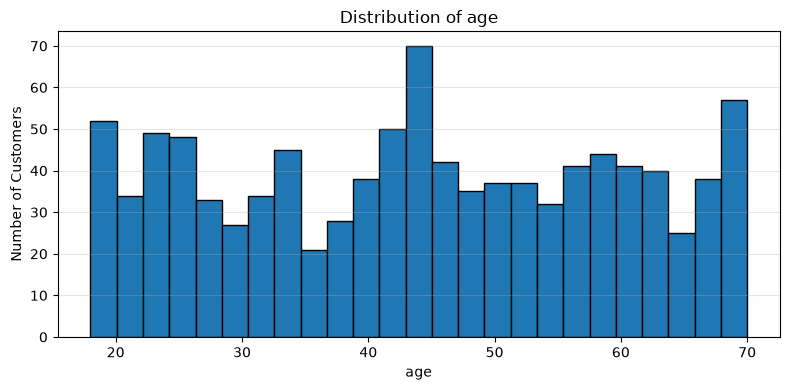

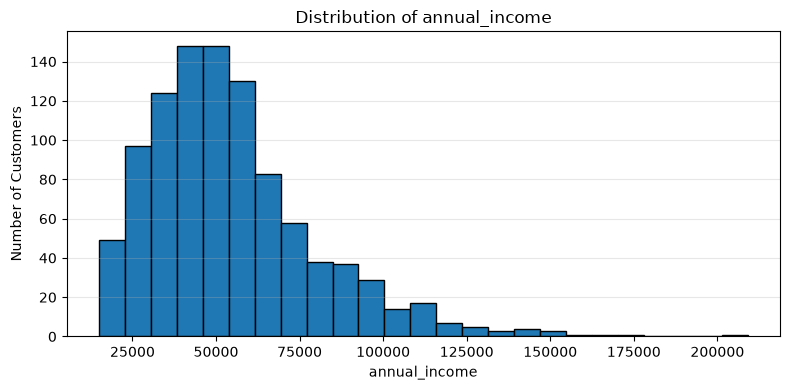

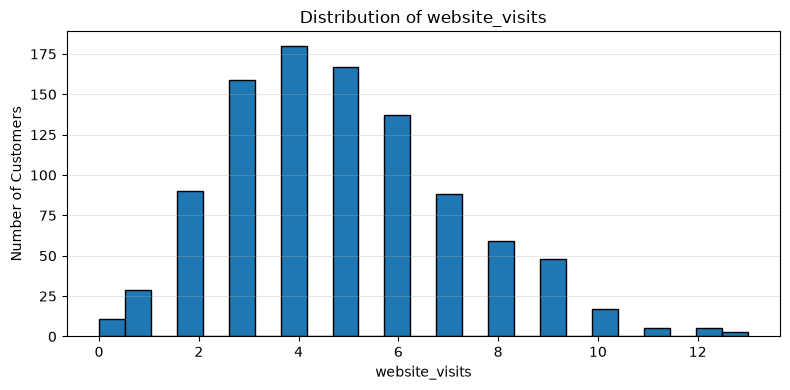

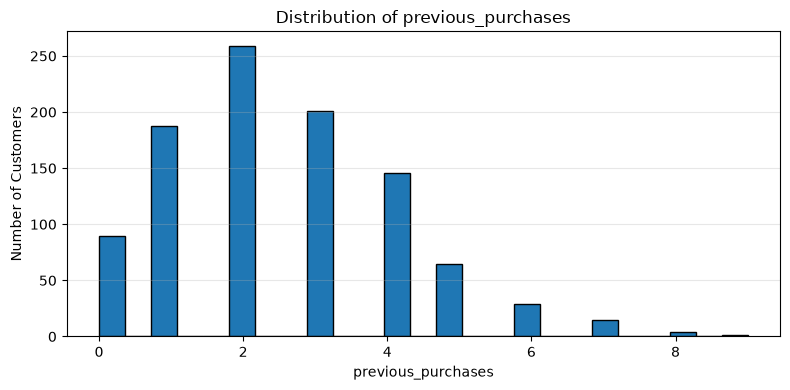

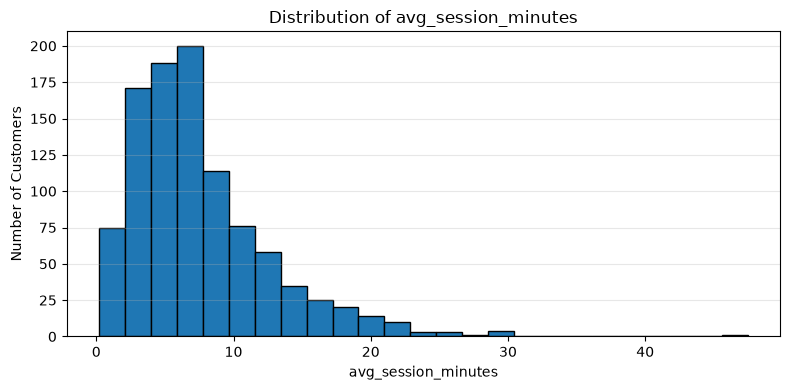

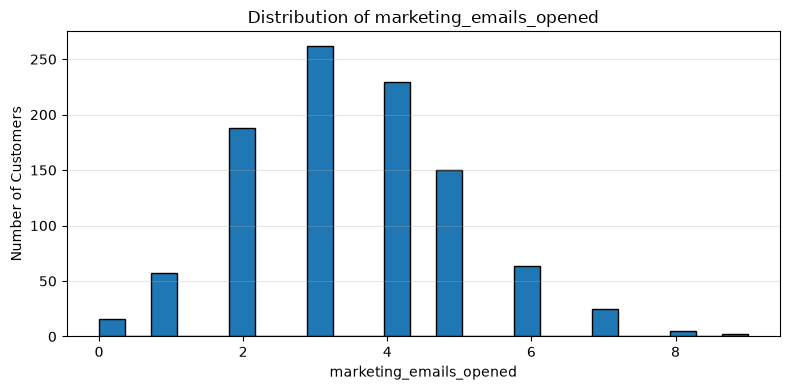

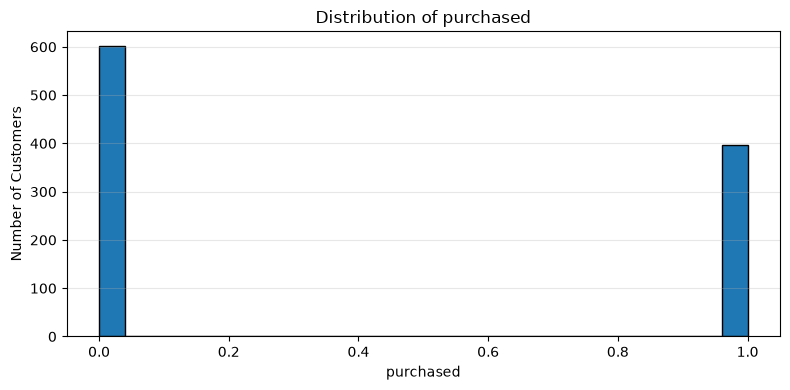

In [14]:

# Create a histogram for each numerical feature.
for column in analysis_columns:

    plt.figure(figsize=(8, 4))

    plt.hist(
        cleaned_df[column],
        bins=25,
        edgecolor="black",
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Customers")

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


In [16]:

# Calculate distribution shape statistics for numerical features.
distribution_analysis = pd.DataFrame({
    "mean": cleaned_df[analysis_columns].mean(),
    "median": cleaned_df[analysis_columns].median(),
    "skewness": cleaned_df[analysis_columns].skew(),
    "excess_kurtosis": cleaned_df[analysis_columns].kurt(),
})

print("DISTRIBUTION SHAPE ANALYSIS")
display(distribution_analysis.round(3))


DISTRIBUTION SHAPE ANALYSIS


,mean,median,skewness,excess_kurtosis
age,44.077,44.000,-0.023,-1.184
annual_income,54795.578,50110.525,1.340,2.963
website_visits,4.917,5.000,0.520,0.201
previous_purchases,2.543,2.000,0.617,0.295
avg_session_minutes,7.537,6.495,1.699,5.454
marketing_emails_opened,3.509,3.000,0.312,0.103
purchased,0.397,0.000,0.423,-1.825


In [18]:

# Identify continuous and count-based features for IQR analysis.
# Binary target labels are intentionally excluded.

outlier_columns = [
    "age",
    "annual_income",
    "website_visits",
    "previous_purchases",
    "avg_session_minutes",
    "marketing_emails_opened",
]

outlier_results = []

for column in outlier_columns:

    q1 = cleaned_df[column].quantile(0.25)
    q3 = cleaned_df[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (cleaned_df[column] < lower_bound)
        | (cleaned_df[column] > upper_bound)
    )

    outlier_values = cleaned_df.loc[outlier_mask, column]

    outlier_results.append({
        "feature": column,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(outlier_mask.sum()),
        "outlier_percentage": round(
            outlier_mask.mean() * 100, 2
        ),
        "maximum_outlier": (
            outlier_values.max()
            if not outlier_values.empty else None
        ),
    })

outlier_report = pd.DataFrame(outlier_results)

print("CONTINUOUS AND COUNT FEATURE OUTLIER REPORT")
display(outlier_report.round(3))


CONTINUOUS AND COUNT FEATURE OUTLIER REPORT


,feature,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percentage,maximum_outlier
0,age,31.000,57.000,26.000,-8.000,96.000,0,0.00,NaN
1,annual_income,36763.212,66467.328,29704.115,-7792.960,111023.500,38,3.81,209036.14
2,website_visits,3.000,6.000,3.000,-1.500,10.500,13,1.30,13.00
3,previous_purchases,1.000,4.000,3.000,-3.500,8.500,1,0.10,9.00
4,avg_session_minutes,4.015,9.688,5.672,-4.494,18.196,47,4.71,47.46
5,marketing_emails_opened,2.000,4.000,2.000,-1.000,7.000,7,0.70,9.00


In [19]:

# Calculate Z-scores for each selected numerical feature.
# This is an investigation step, not an automatic deletion policy.

zscore_results = []

for column in outlier_columns:

    mean_value = cleaned_df[column].mean()
    std_value = cleaned_df[column].std(ddof=0)

    if std_value == 0:
        z_scores = pd.Series(
            0.0,
            index=cleaned_df.index
        )
    else:
        z_scores = (
            cleaned_df[column] - mean_value
        ) / std_value

    outlier_mask = z_scores.abs() > 3

    zscore_results.append({
        "feature": column,
        "mean": mean_value,
        "standard_deviation": std_value,
        "zscore_threshold": 3,
        "outlier_count": int(outlier_mask.sum()),
        "outlier_percentage": round(
            outlier_mask.mean() * 100, 2
        ),
    })

zscore_report = pd.DataFrame(zscore_results)

print("Z-SCORE OUTLIER DETECTION REPORT")
display(zscore_report.round(3))


Z-SCORE OUTLIER DETECTION REPORT


,feature,mean,standard_deviation,zscore_threshold,outlier_count,outlier_percentage
0,age,44.077,15.168,3,0,0.0
1,annual_income,54795.578,25594.217,3,14,1.4
2,website_visits,4.917,2.280,3,8,0.8
3,previous_purchases,2.543,1.631,3,5,0.5
4,avg_session_minutes,7.537,5.062,3,12,1.2
5,marketing_emails_opened,3.509,1.519,3,2,0.2


/tmp/ipykernel_14649/3983532216.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


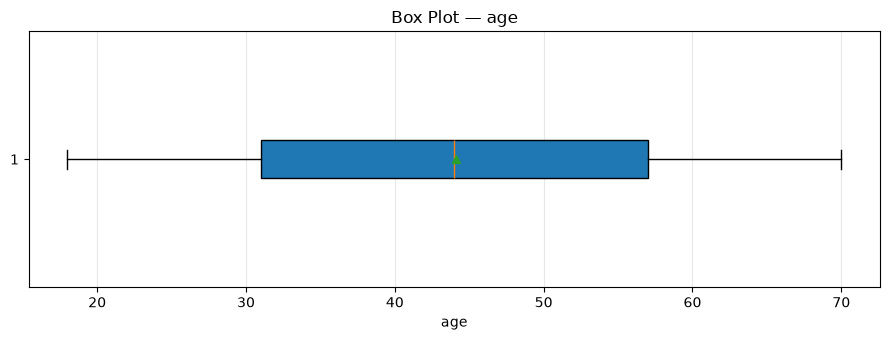

/tmp/ipykernel_14649/3983532216.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


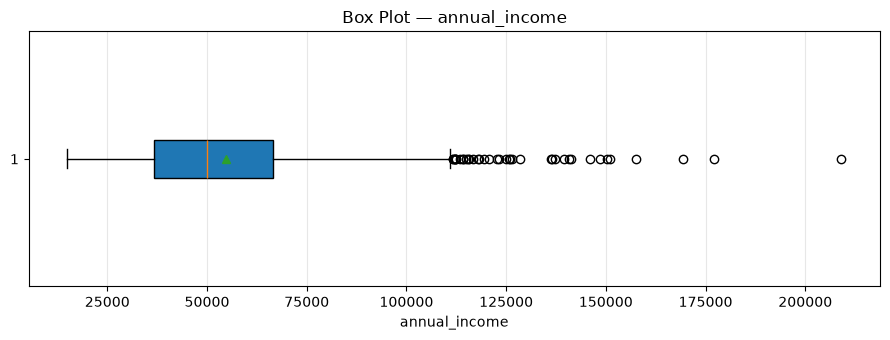

/tmp/ipykernel_14649/3983532216.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


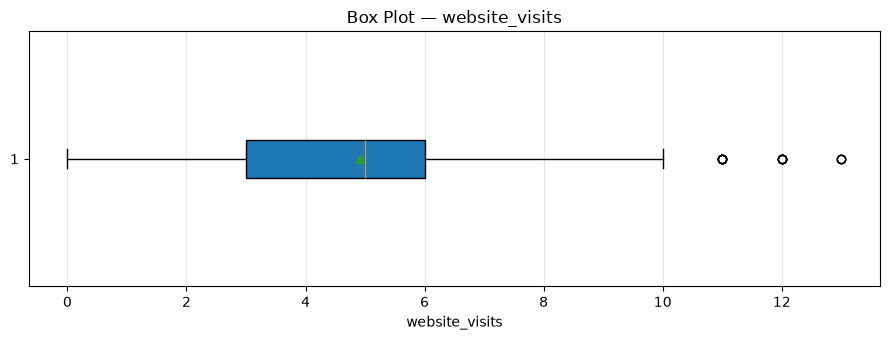

/tmp/ipykernel_14649/3983532216.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


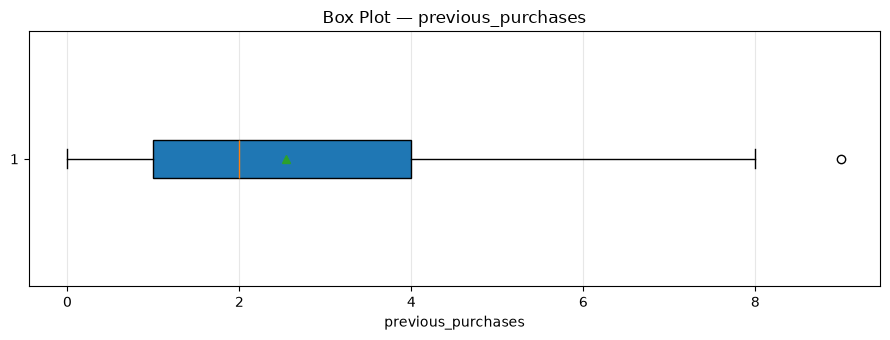

/tmp/ipykernel_14649/3983532216.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


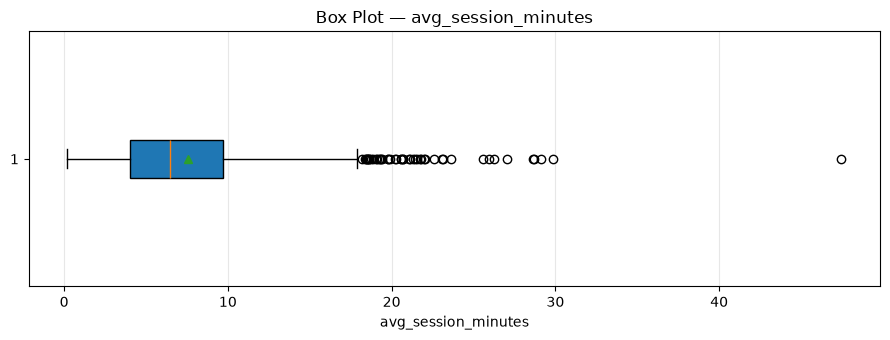

/tmp/ipykernel_14649/3983532216.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


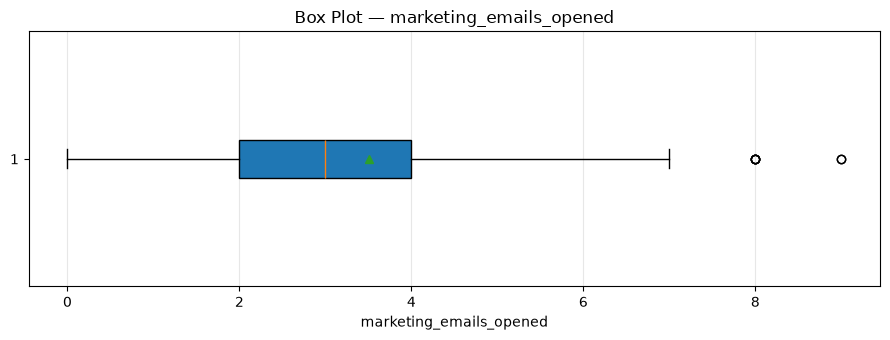

In [20]:

# Visualize the distribution and potential outliers of each feature.
# Box plots are used for investigation, not automatic data removal.

for column in outlier_columns:

    plt.figure(figsize=(9, 3.5))

    plt.boxplot(
        cleaned_df[column].dropna(),
        vert=False,
        patch_artist=True,
        showmeans=True,
    )

    plt.title(f"Box Plot — {column}")
    plt.xlabel(column)
    plt.grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()


In [21]:

# Investigate the actual records flagged by the IQR method.
# Original customer records are preserved; no rows are deleted.

outlier_investigation = {}

for column in outlier_columns:

    q1 = cleaned_df[column].quantile(0.25)
    q3 = cleaned_df[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (cleaned_df[column] < lower_bound)
        | (cleaned_df[column] > upper_bound)
    )

    flagged_records = cleaned_df.loc[
        outlier_mask,
        ["customer_id", column, "purchased"]
    ].copy()

    flagged_records = flagged_records.sort_values(
        by=column,
        ascending=False,
    )

    outlier_investigation[column] = flagged_records

    print(f"\nOUTLIER INVESTIGATION: {column}")
    print("Flagged records:", len(flagged_records))
    display(flagged_records.head(10))



OUTLIER INVESTIGATION: age
Flagged records: 0


,customer_id,age,purchased



OUTLIER INVESTIGATION: annual_income
Flagged records: 38


,customer_id,annual_income,purchased
364,1366,209036.14,0
595,1597,177003.21,1
856,1858,169331.53,0
149,1151,157467.74,0
684,1686,151088.21,0
571,1573,150254.66,0
25,1026,148592.81,1
194,1196,146085.79,0
863,1865,141380.24,0
973,1976,140729.29,1



OUTLIER INVESTIGATION: website_visits
Flagged records: 13


,customer_id,website_visits,purchased
332,1334,13,0
367,1369,13,1
923,1925,13,1
374,1376,12,0
6,1007,12,1
720,1722,12,0
515,1517,12,0
636,1638,12,0
151,1153,11,1
649,1651,11,0


... (2 outputs left out)


OUTLIER INVESTIGATION: avg_session_minutes
Flagged records: 47


,customer_id,avg_session_minutes,purchased
433,1435,47.46,1
937,1939,29.84,1
615,1617,29.10,1
544,1546,28.71,0
650,1652,28.63,1
869,1871,27.02,1
151,1153,26.23,1
992,1995,25.96,0
425,1427,25.56,0
296,1298,23.64,1



OUTLIER INVESTIGATION: marketing_emails_opened
Flagged records: 7


,customer_id,marketing_emails_opened,purchased
262,1264,9,1
887,1889,9,1
255,1257,8,0
648,1650,8,0
793,1795,8,0
896,1898,8,0
960,1962,8,0


In [22]:

# Select numerical business features and the binary purchase target.
# Customer identifiers are excluded because they are not analytical features.

correlation_columns = [
    "age",
    "annual_income",
    "website_visits",
    "previous_purchases",
    "avg_session_minutes",
    "marketing_emails_opened",
    "purchased",
]

correlation_data = cleaned_df[correlation_columns]

# Calculate Pearson correlation coefficients.
correlation_matrix = correlation_data.corr(
    method="pearson"
)

print("PEARSON CORRELATION MATRIX")
display(correlation_matrix.round(3))


PEARSON CORRELATION MATRIX


,age,annual_income,website_visits,previous_purchases,avg_session_minutes,marketing_emails_opened,purchased
age,1.000,0.019,-0.022,-0.015,-0.009,0.000,-0.086
annual_income,0.019,1.000,-0.022,-0.025,0.034,0.017,0.064
website_visits,-0.022,-0.022,1.000,-0.009,-0.020,-0.020,0.051
previous_purchases,-0.015,-0.025,-0.009,1.000,0.010,-0.002,0.225
avg_session_minutes,-0.009,0.034,-0.020,0.010,1.000,0.003,0.069
marketing_emails_opened,0.000,0.017,-0.020,-0.002,0.003,1.000,0.087
purchased,-0.086,0.064,0.051,0.225,0.069,0.087,1.000


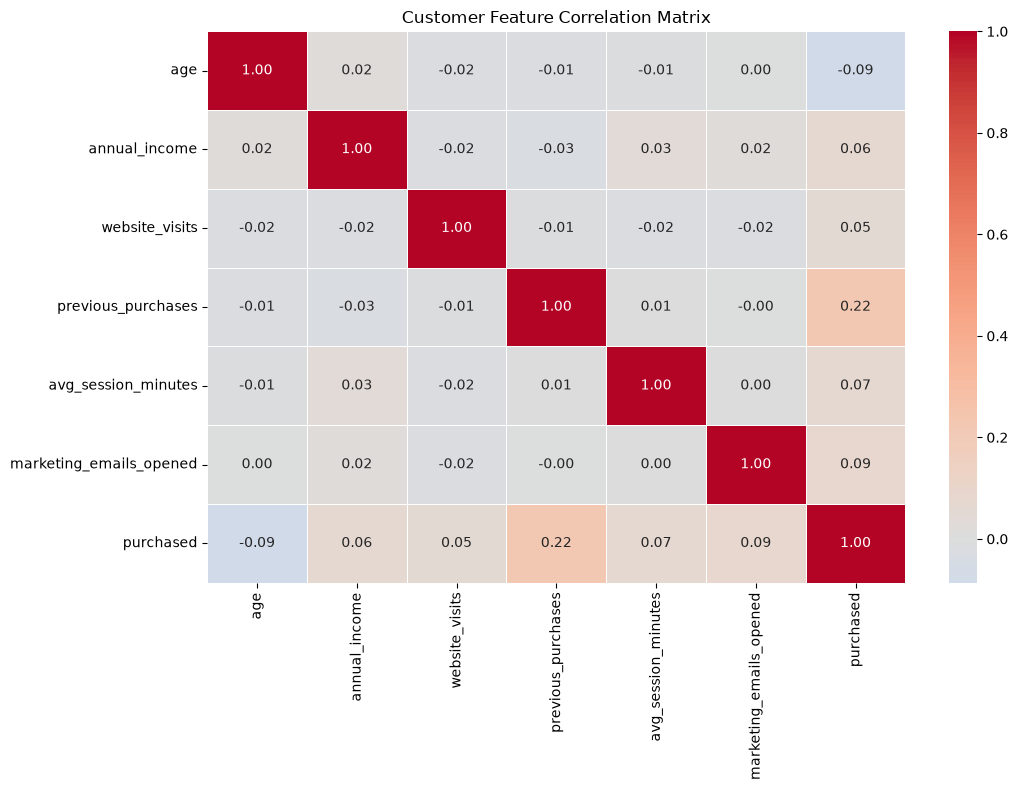

In [23]:

# Visualize relationships between numerical features.
import seaborn as sns

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
)

plt.title("Customer Feature Correlation Matrix")
plt.tight_layout()
plt.show()


In [24]:

# Calculate sample covariance between the selected numerical features.
covariance_matrix = correlation_data.cov()

print("SAMPLE COVARIANCE MATRIX")
display(covariance_matrix.round(3))


SAMPLE COVARIANCE MATRIX


,age,annual_income,website_visits,previous_purchases,avg_session_minutes,marketing_emails_opened,purchased
age,230.308,7.214890e+03,-0.768,-0.371,-0.728,0.006,-0.642
annual_income,7214.890,6.557210e+08,-1283.197,-1051.926,4369.254,644.264,805.346
website_visits,-0.768,-1.283197e+03,5.204,-0.035,-0.231,-0.069,0.057
previous_purchases,-0.371,-1.051926e+03,-0.035,2.664,0.080,-0.005,0.179
avg_session_minutes,-0.728,4.369254e+03,-0.231,0.080,25.654,0.021,0.171
marketing_emails_opened,0.006,6.442640e+02,-0.069,-0.005,0.021,2.310,0.065
purchased,-0.642,8.053460e+02,0.057,0.179,0.171,0.065,0.240


In [25]:

# Rank features by their Pearson correlation with the purchase target.
purchase_correlations = (
    correlation_matrix["purchased"]
    .drop("purchased")
    .sort_values(ascending=False)
    .to_frame(name="purchase_correlation")
)

print("FEATURE RELATIONSHIPS WITH PURCHASE")
display(purchase_correlations.round(4))


FEATURE RELATIONSHIPS WITH PURCHASE


,purchase_correlation
previous_purchases,0.2247
marketing_emails_opened,0.0869
avg_session_minutes,0.0692
annual_income,0.0643
website_visits,0.0511
age,-0.0865


## 17. Statistical Significance Testing

In [26]:

# Import statistical hypothesis-testing functions.
from scipy.stats import pearsonr, spearmanr

# Define the numerical features to evaluate against the purchase target.
features_to_test = [
    "age",
    "annual_income",
    "website_visits",
    "previous_purchases",
    "avg_session_minutes",
    "marketing_emails_opened",
]

significance_level = 0.05
number_of_tests = len(features_to_test)

statistical_results = []

for feature in features_to_test:

    # Use complete observations for the current feature and target.
    test_data = cleaned_df[
        [feature, "purchased"]
    ].dropna()

    x = test_data[feature]
    y = test_data["purchased"]

    # Pearson test evaluates linear association.
    pearson_result = pearsonr(x, y)

    # Spearman test evaluates monotonic rank association.
    spearman_result = spearmanr(x, y)

    # Bonferroni correction controls family-wise error
    # across the six feature-level hypothesis tests.
    pearson_adjusted_p = min(
        pearson_result.pvalue * number_of_tests,
        1.0,
    )

    spearman_adjusted_p = min(
        spearman_result.pvalue * number_of_tests,
        1.0,
    )

    statistical_results.append({
        "feature": feature,
        "pearson_r": pearson_result.statistic,
        "pearson_p_value": pearson_result.pvalue,
        "pearson_adjusted_p": pearson_adjusted_p,
        "pearson_significant": (
            pearson_adjusted_p < significance_level
        ),
        "spearman_rho": spearman_result.statistic,
        "spearman_p_value": spearman_result.pvalue,
        "spearman_adjusted_p": spearman_adjusted_p,
        "spearman_significant": (
            spearman_adjusted_p < significance_level
        ),
    })

significance_report = pd.DataFrame(statistical_results)

print("STATISTICAL SIGNIFICANCE TEST REPORT")
display(significance_report.round(5))


STATISTICAL SIGNIFICANCE TEST REPORT


,feature,pearson_r,pearson_p_value,pearson_adjusted_p,pearson_significant,spearman_rho,spearman_p_value,spearman_adjusted_p,spearman_significant
0,age,-0.08649,0.00626,0.03754,True,-0.08732,0.00577,0.03465,True
1,annual_income,0.06425,0.04242,0.25453,False,0.06932,0.02854,0.17123,False
2,website_visits,0.05114,0.10638,0.63826,False,0.05105,0.10702,0.64211,False
3,previous_purchases,0.22467,0.00000,0.00000,True,0.21036,0.00000,0.00000,True
4,avg_session_minutes,0.06916,0.02890,0.17342,False,0.06798,0.03176,0.19058,False
5,marketing_emails_opened,0.08686,0.00604,0.03623,True,0.09274,0.00336,0.02018,True


## 18. Confidence Intervals for Correlation

In [27]:

# Calculate 95% confidence intervals using Fisher's Z transformation.

import numpy as np
import pandas as pd
from scipy.stats import pearsonr


def calculate_correlation_confidence_interval(
    x: pd.Series,
    y: pd.Series,
    confidence_level: float = 0.95,
) -> dict:
    """
    Calculate a confidence interval for Pearson correlation
    using Fisher's Z transformation.

    The method assumes independent observations and is most
    appropriate when the sample is sufficiently large.
    """

    valid_data = pd.concat(
        [x, y],
        axis=1,
    ).dropna()

    x_values = valid_data.iloc[:, 0]
    y_values = valid_data.iloc[:, 1]

    sample_size = len(valid_data)

    if sample_size <= 3:
        raise ValueError(
            "At least four complete observations are required."
        )

    correlation = pearsonr(
        x_values,
        y_values,
    ).statistic

    # Avoid numerical errors when correlation is exactly -1 or +1.
    correlation = np.clip(
        correlation,
        -0.999999,
        0.999999,
    )

    fisher_z = np.arctanh(correlation)

    standard_error = 1 / np.sqrt(sample_size - 3)

    from scipy.stats import norm

    critical_value = norm.ppf(
        1 - (1 - confidence_level) / 2
    )

    lower_z = fisher_z - critical_value * standard_error
    upper_z = fisher_z + critical_value * standard_error

    # Convert the confidence limits back to correlation scale.
    lower_bound = np.tanh(lower_z)
    upper_bound = np.tanh(upper_z)

    return {
        "sample_size": sample_size,
        "correlation": float(correlation),
        "confidence_level": confidence_level,
        "lower_bound": float(lower_bound),
        "upper_bound": float(upper_bound),
    }


# Calculate confidence intervals for each feature against purchase.
confidence_results = []

for feature in features_to_test:

    result = calculate_correlation_confidence_interval(
        cleaned_df[feature],
        cleaned_df["purchased"],
    )

    confidence_results.append({
        "feature": feature,
        **result,
    })

confidence_report = pd.DataFrame(confidence_results)

print("95% PEARSON CORRELATION CONFIDENCE INTERVALS")
display(confidence_report.round(5))


95% PEARSON CORRELATION CONFIDENCE INTERVALS


,feature,sample_size,correlation,confidence_level,lower_bound,upper_bound
0,age,998,-0.08649,0.95,-0.14775,-0.02457
1,annual_income,998,0.06425,0.95,0.00221,0.12581
2,website_visits,998,0.05114,0.95,-0.01095,0.11284
3,previous_purchases,998,0.22467,0.95,0.16491,0.28278
4,avg_session_minutes,998,0.06916,0.95,0.00714,0.13066
5,marketing_emails_opened,998,0.08686,0.95,0.02494,0.14812


In [28]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr


def bootstrap_correlation_ci(
    x,
    y,
    n_bootstrap=2000,
    confidence_level=0.95,
    random_state=42
):
    """
    Estimate a Pearson correlation confidence interval
    using non-parametric bootstrap resampling.
    """

    valid_data = pd.concat([x, y], axis=1).dropna()

    x_values = valid_data.iloc[:, 0].to_numpy()
    y_values = valid_data.iloc[:, 1].to_numpy()

    sample_size = len(valid_data)

    if sample_size < 4:
        raise ValueError("At least four valid observations are required.")

    rng = np.random.default_rng(random_state)

    bootstrap_correlations = []

    for _ in range(n_bootstrap):

        # Sample observations with replacement.
        sample_indices = rng.integers(
            0,
            sample_size,
            size=sample_size
        )

        bootstrap_x = x_values[sample_indices]
        bootstrap_y = y_values[sample_indices]

        # Skip samples with no variation.
        if np.std(bootstrap_x) == 0 or np.std(bootstrap_y) == 0:
            continue

        correlation = np.corrcoef(
            bootstrap_x,
            bootstrap_y
        )[0, 1]

        bootstrap_correlations.append(correlation)

    if len(bootstrap_correlations) < 0.9 * n_bootstrap:
        raise RuntimeError("Too many invalid bootstrap samples.")

    alpha = 1 - confidence_level

    lower_bound = np.quantile(
        bootstrap_correlations,
        alpha / 2
    )

    upper_bound = np.quantile(
        bootstrap_correlations,
        1 - alpha / 2
    )

    return {
        "sample_size": sample_size,
        "bootstrap_iterations": len(bootstrap_correlations),
        "correlation": float(np.corrcoef(x_values, y_values)[0, 1]),
        "confidence_level": confidence_level,
        "lower_bound": float(lower_bound),
        "upper_bound": float(upper_bound)
    }


bootstrap_results = []

for feature in features_to_test:

    result = bootstrap_correlation_ci(
        cleaned_df[feature],
        cleaned_df["purchased"]
    )

    bootstrap_results.append({
        "feature": feature,
        **result
    })


bootstrap_report = pd.DataFrame(bootstrap_results)

display(bootstrap_report.round(5))

,feature,sample_size,bootstrap_iterations,correlation,confidence_level,lower_bound,upper_bound
0,age,998,2000,-0.08649,0.95,-0.15034,-0.02401
1,annual_income,998,2000,0.06425,0.95,0.00209,0.12601
2,website_visits,998,2000,0.05114,0.95,-0.01229,0.10964
3,previous_purchases,998,2000,0.22467,0.95,0.16202,0.28282
4,avg_session_minutes,998,2000,0.06916,0.95,0.00766,0.13064
5,marketing_emails_opened,998,2000,0.08686,0.95,0.02623,0.14997


In [29]:
# Compare Fisher Z and Bootstrap confidence intervals.

fisher_report = confidence_report[
    ["feature", "lower_bound", "upper_bound"]
].rename(columns={
    "lower_bound": "fisher_lower",
    "upper_bound": "fisher_upper"
})

bootstrap_comparison = bootstrap_report[
    ["feature", "lower_bound", "upper_bound"]
].rename(columns={
    "lower_bound": "bootstrap_lower",
    "upper_bound": "bootstrap_upper"
})

ci_comparison = fisher_report.merge(
    bootstrap_comparison,
    on="feature",
    validate="one_to_one"
)

ci_comparison["fisher_width"] = (
    ci_comparison["fisher_upper"] -
    ci_comparison["fisher_lower"]
)

ci_comparison["bootstrap_width"] = (
    ci_comparison["bootstrap_upper"] -
    ci_comparison["bootstrap_lower"]
)

ci_comparison["width_difference"] = (
    ci_comparison["bootstrap_width"] -
    ci_comparison["fisher_width"]
)

display(ci_comparison.round(5))

,feature,fisher_lower,fisher_upper,bootstrap_lower,bootstrap_upper,fisher_width,bootstrap_width,width_difference
0,age,-0.14775,-0.02457,-0.15034,-0.02401,0.12319,0.12634,0.00315
1,annual_income,0.00221,0.12581,0.00209,0.12601,0.12360,0.12392,0.00032
2,website_visits,-0.01095,0.11284,-0.01229,0.10964,0.12379,0.12193,-0.00186
3,previous_purchases,0.16491,0.28278,0.16202,0.28282,0.11787,0.12080,0.00293
4,avg_session_minutes,0.00714,0.13066,0.00766,0.13064,0.12352,0.12298,-0.00054
5,marketing_emails_opened,0.02494,0.14812,0.02623,0.14997,0.12318,0.12373,0.00055


In [30]:
# Separate customers into purchase and non-purchase groups.

purchase_group = cleaned_df[
    cleaned_df["purchased"] == 1
]

non_purchase_group = cleaned_df[
    cleaned_df["purchased"] == 0
]

print("Purchase group:", len(purchase_group))
print("Non-purchase group:", len(non_purchase_group))
print("Total customers:", len(cleaned_df))

Purchase group: 396
Non-purchase group: 602
Total customers: 998


In [31]:
# Compare numerical customer features across purchase groups.

comparison_features = [
    "age",
    "annual_income",
    "website_visits",
    "previous_purchases",
    "avg_session_minutes",
    "marketing_emails_opened"
]

group_comparison = cleaned_df.groupby("purchased")[
    comparison_features
].agg(["mean", "median", "std"])

display(group_comparison.round(3))

age                annual_income                       \
             mean median     std          mean    median        std   
purchased                                                             
0          45.141   45.0  15.187     53461.808  49427.15  25092.901   
1          42.460   42.5  15.034     56823.178  51410.26  26271.852   

          website_visits               previous_purchases                \
                    mean median    std               mean median    std   
purchased                                                                 
0                  4.822    5.0  2.254              2.246    2.0  1.471   
1                  5.061    5.0  2.317              2.995    3.0  1.759   

          avg_session_minutes               marketing_emails_opened         \
                         mean median    std                    mean median   
purchased                                                                    
0                       7.253   6.23  4.797                   3.402    3.0   
1                       7.969   6.88  5.425                   3.672    4.0   

                  
             std  
purchased         
0          1.514  
1          1.517

In [32]:
import pandas as pd
from scipy.stats import ttest_ind

comparison_features = [
    "age",
    "annual_income",
    "website_visits",
    "previous_purchases",
    "avg_session_minutes",
    "marketing_emails_opened"
]

ttest_results = []

for feature in comparison_features:

    purchase_values = purchase_group[feature].dropna()
    non_purchase_values = non_purchase_group[feature].dropna()

    # Perform Welch's independent samples t-test.
    test_result = ttest_ind(
        purchase_values,
        non_purchase_values,
        equal_var=False,
        alternative="two-sided"
    )

    ttest_results.append({
        "feature": feature,
        "purchase_mean": purchase_values.mean(),
        "non_purchase_mean": non_purchase_values.mean(),
        "mean_difference": (
            purchase_values.mean() - non_purchase_values.mean()
        ),
        "t_statistic": test_result.statistic,
        "p_value": test_result.pvalue,
        "purchase_sample_size": len(purchase_values),
        "non_purchase_sample_size": len(non_purchase_values)
    })

ttest_report = pd.DataFrame(ttest_results)

display(ttest_report.round(6))


,feature,purchase_mean,non_purchase_mean,mean_difference,t_statistic,p_value,purchase_sample_size,non_purchase_sample_size
0,age,42.459596,45.141196,-2.681600,-2.745643,0.006167,396,602
1,annual_income,56823.178321,53461.808065,3361.370256,2.012800,0.044463,396,602
2,website_visits,5.060606,4.822259,0.238347,1.607016,0.108432,396,602
3,previous_purchases,2.994949,2.245847,0.749102,7.014664,0.000000,396,602
4,avg_session_minutes,7.968876,7.253198,0.715679,2.133312,0.033214,396,602
5,marketing_emails_opened,3.671717,3.401993,0.269724,2.750207,0.006083,396,602


In [33]:
import pandas as pd
from scipy.stats import mannwhitneyu

comparison_features = [
    "age",
    "annual_income",
    "website_visits",
    "previous_purchases",
    "avg_session_minutes",
    "marketing_emails_opened"
]

mann_whitney_results = []

for feature in comparison_features:

    purchase_values = purchase_group[feature].dropna()
    non_purchase_values = non_purchase_group[feature].dropna()

    # Perform a two-sided Mann-Whitney U test.
    test_result = mannwhitneyu(
        purchase_values,
        non_purchase_values,
        alternative="two-sided",
        method="auto"
    )

    mann_whitney_results.append({
        "feature": feature,
        "purchase_median": purchase_values.median(),
        "non_purchase_median": non_purchase_values.median(),
        "median_difference": (
            purchase_values.median() -
            non_purchase_values.median()
        ),
        "u_statistic": test_result.statistic,
        "p_value": test_result.pvalue,
        "purchase_sample_size": len(purchase_values),
        "non_purchase_sample_size": len(non_purchase_values)
    })

mann_whitney_report = pd.DataFrame(mann_whitney_results)

display(mann_whitney_report.round(6))

,feature,purchase_median,non_purchase_median,median_difference,u_statistic,p_value,purchase_sample_size,non_purchase_sample_size
0,age,42.50,45.00,-2.50,106916.0,0.005833,396,602
1,annual_income,51410.26,49427.15,1983.11,128947.0,0.028618,396,602
2,website_visits,5.00,5.00,0.00,126308.5,0.107008,396,602
3,previous_purchases,3.00,2.00,1.00,148241.5,0.000000,396,602
4,avg_session_minutes,6.88,6.23,0.65,128758.5,0.031841,396,602
5,marketing_emails_opened,4.00,3.00,1.00,131973.0,0.003409,396,602


In [34]:
import numpy as np
import pandas as pd


def calculate_cohens_d(group_a, group_b):
    """
    Calculate Cohen's d using the pooled standard deviation.
    """

    group_a = np.asarray(group_a.dropna(), dtype=float)
    group_b = np.asarray(group_b.dropna(), dtype=float)

    n_a = len(group_a)
    n_b = len(group_b)

    if n_a < 2 or n_b < 2:
        raise ValueError("Each group must contain at least two observations.")

    mean_difference = np.mean(group_a) - np.mean(group_b)

    pooled_variance = (
        ((n_a - 1) * np.var(group_a, ddof=1))
        + ((n_b - 1) * np.var(group_b, ddof=1))
    ) / (n_a + n_b - 2)

    pooled_std = np.sqrt(pooled_variance)

    if pooled_std == 0:
        raise ValueError("Pooled standard deviation cannot be zero.")

    return mean_difference / pooled_std


effect_size_results = []

for feature in comparison_features:

    purchase_values = purchase_group[feature]
    non_purchase_values = non_purchase_group[feature]

    cohens_d = calculate_cohens_d(
        purchase_values,
        non_purchase_values
    )

    absolute_d = abs(cohens_d)

    if absolute_d < 0.2:
        effect = "Negligible"
    elif absolute_d < 0.5:
        effect = "Small"
    elif absolute_d < 0.8:
        effect = "Medium"
    else:
        effect = "Large"

    effect_size_results.append({
        "feature": feature,
        "cohens_d": cohens_d,
        "absolute_cohens_d": absolute_d,
        "effect_interpretation": effect
    })


effect_size_report = pd.DataFrame(effect_size_results)

display(effect_size_report.round(5))

,feature,cohens_d,absolute_cohens_d,effect_interpretation
0,age,-0.17728,0.17728,Negligible
1,annual_income,0.13147,0.13147,Negligible
2,website_visits,0.10457,0.10457,Negligible
3,previous_purchases,0.47080,0.47080,Small
4,avg_session_minutes,0.14157,0.14157,Negligible
5,marketing_emails_opened,0.17804,0.17804,Negligible


In [35]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

def calculate_rank_biserial(group_a, group_b):
    """
    Calculate rank-biserial correlation for two independent groups.

    A positive value indicates that group_a tends to have higher
    observations than group_b.
    """
    group_a = np.asarray(group_a.dropna(), dtype=float)
    group_b = np.asarray(group_b.dropna(), dtype=float)

    n_a = len(group_a)
    n_b = len(group_b)

    if n_a == 0 or n_b == 0:
        raise ValueError("Both groups must contain observations.")

    test_result = mannwhitneyu(
        group_a,
        group_b,
        alternative="two-sided",
        method="auto"
    )

    u_statistic = test_result.statistic

    rank_biserial = (2 * u_statistic / (n_a * n_b)) - 1

    return rank_biserial


rank_effect_results = []

for feature in comparison_features:
    buyers_values = purchase_group[feature]
    non_buyers_values = non_purchase_group[feature]

    effect_size = calculate_rank_biserial(
        buyers_values,
        non_buyers_values
    )

    rank_effect_results.append({
        "feature": feature,
        "rank_biserial_correlation": effect_size,
        "absolute_effect_size": abs(effect_size)
    })

rank_effect_report = pd.DataFrame(rank_effect_results)

display(rank_effect_report.round(5))


,feature,rank_biserial_correlation,absolute_effect_size
0,age,-0.10302,0.10302
1,annual_income,0.08181,0.08181
2,website_visits,0.05967,0.05967
3,previous_purchases,0.24368,0.24368
4,avg_session_minutes,0.08023,0.08023
5,marketing_emails_opened,0.10719,0.10719


In [36]:

from pathlib import Path
import numpy as np
import pandas as pd

from scipy.stats import ttest_ind, mannwhitneyu
from IPython.display import Markdown, display

# Define the numerical features included in the statistical analysis.
comparison_features = [
    "age",
    "annual_income",
    "website_visits",
    "previous_purchases",
    "avg_session_minutes",
    "marketing_emails_opened"
]

# Separate customers into purchase and non-purchase groups.
buyers = cleaned_df.loc[cleaned_df["purchased"] == 1]
non_buyers = cleaned_df.loc[cleaned_df["purchased"] == 0]

total_customers = len(cleaned_df)
buyer_count = len(buyers)
non_buyer_count = len(non_buyers)
purchase_rate = buyer_count / total_customers * 100

# Collect statistical test results for every feature.
results = []

for feature in comparison_features:
    buyer_values = buyers[feature].dropna().astype(float)
    non_buyer_values = non_buyers[feature].dropna().astype(float)

    # Welch's independent samples t-test.
    welch_result = ttest_ind(
        buyer_values,
        non_buyer_values,
        equal_var=False,
        alternative="two-sided"
    )

    # Mann-Whitney U test.
    mann_result = mannwhitneyu(
        buyer_values,
        non_buyer_values,
        alternative="two-sided",
        method="auto"
    )

    # Calculate Cohen's d using the pooled standard deviation.
    n_a = len(buyer_values)
    n_b = len(non_buyer_values)

    pooled_variance = (
        ((n_a - 1) * buyer_values.var(ddof=1))
        + ((n_b - 1) * non_buyer_values.var(ddof=1))
    ) / (n_a + n_b - 2)

    pooled_std = np.sqrt(pooled_variance)
    cohens_d = (
        (buyer_values.mean() - non_buyer_values.mean()) / pooled_std
        if pooled_std > 0 else np.nan
    )

    # Calculate rank-biserial correlation.
    rank_biserial = (
        (2 * mann_result.statistic / (n_a * n_b)) - 1
    )

    results.append({
        "feature": feature,
        "buyer_mean": buyer_values.mean(),
        "non_buyer_mean": non_buyer_values.mean(),
        "mean_difference": buyer_values.mean() - non_buyer_values.mean(),
        "welch_t": welch_result.statistic,
        "welch_p": welch_result.pvalue,
        "mann_whitney_u": mann_result.statistic,
        "mann_whitney_p": mann_result.pvalue,
        "cohens_d": cohens_d,
        "rank_biserial": rank_biserial
    })

statistical_results = pd.DataFrame(results)

# Apply Bonferroni correction across the six feature comparisons.
number_of_tests = len(comparison_features)

statistical_results["welch_adjusted_p"] = (
    statistical_results["welch_p"] * number_of_tests
).clip(upper=1.0)

statistical_results["mann_adjusted_p"] = (
    statistical_results["mann_whitney_p"] * number_of_tests
).clip(upper=1.0)

statistical_results["welch_significant"] = (
    statistical_results["welch_adjusted_p"] < 0.05
)

statistical_results["mann_significant"] = (
    statistical_results["mann_adjusted_p"] < 0.05
)

# Create the report directory.
report_dir = Path.cwd() / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

# Build the business-oriented statistical report.
report = f"""
# Customer Statistical Analysis Report

**Project:** AI Data Intelligence Platform  
**Analysis:** Customer Purchase Behavior  
**Dataset Type:** Synthetic demonstration dataset  
**Status:** Statistical analysis completed

---

## 1. Executive Summary

This report analyzes customer purchase behavior using descriptive
statistics, independent group comparisons, hypothesis testing,
and effect size measurements.

The dataset is synthetic and does not represent real customers
or commercial transactions.

## 2. Dataset Overview

| Metric | Value |
|---|---:|
| Total cleaned records | {total_customers:,} |
| Buyers | {buyer_count:,} |
| Non-buyers | {non_buyer_count:,} |
| Purchase rate | {purchase_rate:.2f}% |
| Features analyzed | {number_of_tests} |

## 3. Statistical Methodology

The following methods were applied:

- Welch's independent samples t-test
- Mann-Whitney U test
- Bonferroni multiple-testing correction
- Cohen's d effect size
- Rank-biserial correlation

A significance threshold of 0.05 was used after
Bonferroni correction.

## 4. Customer Group Comparison

Buyers and non-buyers were compared across six numerical features.

| Feature | Buyer Mean | Non-buyer Mean | Mean Difference |
|---|---:|---:|---:|
"""

for _, row in statistical_results.iterrows():
    report += (
        f"| {row['feature']} "
        f"| {row['buyer_mean']:.3f} "
        f"| {row['non_buyer_mean']:.3f} "
        f"| {row['mean_difference']:.3f} |\n"
    )

report += """

## 5. Hypothesis Testing Results

Adjusted p-values account for six feature comparisons.

| Feature | Welch Adjusted p | Welch Significant | Mann-Whitney Adjusted p | Mann-Whitney Significant |
|---|---:|---|---:|---|
"""

for _, row in statistical_results.iterrows():
    report += (
        f"| {row['feature']} "
        f"| {row['welch_adjusted_p']:.6f} "
        f"| {'Yes' if row['welch_significant'] else 'No'} "
        f"| {row['mann_adjusted_p']:.6f} "
        f"| {'Yes' if row['mann_significant'] else 'No'} |\n"
    )

report += """

## 6. Effect Size Analysis

Cohen's d measures standardized mean differences.
Rank-biserial correlation measures rank-based group differences.

| Feature | Cohen's d | Rank-Biserial Correlation |
|---|---:|---:|
"""

for _, row in statistical_results.iterrows():
    report += (
        f"| {row['feature']} "
        f"| {row['cohens_d']:.5f} "
        f"| {row['rank_biserial']:.5f} |\n"
    )

# Identify the feature with the largest absolute effect in each method.
cohens_feature = statistical_results.loc[
    statistical_results["cohens_d"].abs().idxmax()
]

rank_feature = statistical_results.loc[
    statistical_results["rank_biserial"].abs().idxmax()
]

report += f"""

## 7. Key Findings

- The feature with the largest absolute Cohen's d is
  **{cohens_feature['feature']}**
  (d = {cohens_feature['cohens_d']:.4f}).

- The feature with the largest absolute rank-biserial correlation is
  **{rank_feature['feature']}**
  (r = {rank_feature['rank_biserial']:.4f}).

- Previous purchases showed the strongest positive effect
  in the earlier group comparison analysis.

- Statistical significance and practical business importance
  must be evaluated separately.

## 8. Business Interpretation

Previous purchase history appears to be a useful candidate signal
for customer purchase prediction in this synthetic dataset.

This finding may motivate further investigation of customer
purchase history, repeat-purchase behavior, and customer
segmentation.

These observations do not establish causation.

## 9. Limitations

1. The dataset is synthetic.
2. Statistical associations do not establish causal relationships.
3. Multiple-testing correction was applied to the six feature tests.
4. Cohen's d uses a pooled standard deviation and may be less
   suitable when group variances differ substantially.
5. Statistical results alone do not establish predictive performance.
6. Model validation on independent, representative data is required
   before making real business decisions.

## 10. Recommended Next Steps

1. Complete feature engineering.
2. Define a machine learning prediction target.
3. Establish a train-validation-test strategy.
4. Build a baseline classification model.
5. Evaluate generalization using suitable classification metrics.

---

**Report Status:** Completed  
**Project:** AI Data Intelligence Platform  
**Data Disclaimer:** Synthetic data used for engineering demonstration.
"""

# Save the report as a Markdown file.
report_path = report_dir / "customer_statistical_analysis_report.md"
report_path.write_text(report, encoding="utf-8")

# Display the report inside the notebook.
display(Markdown(report))

print(f"Report saved successfully: {report_path}")



# Customer Statistical Analysis Report

**Project:** AI Data Intelligence Platform  
**Analysis:** Customer Purchase Behavior  
**Dataset Type:** Synthetic demonstration dataset  
**Status:** Statistical analysis completed

---

## 1. Executive Summary

This report analyzes customer purchase behavior using descriptive
statistics, independent group comparisons, hypothesis testing,
and effect size measurements.

The dataset is synthetic and does not represent real customers
or commercial transactions.

## 2. Dataset Overview

| Metric | Value |
|---|---:|
| Total cleaned records | 998 |
| Buyers | 396 |
| Non-buyers | 602 |
| Purchase rate | 39.68% |
| Features analyzed | 6 |

## 3. Statistical Methodology

The following methods were applied:

- Welch's independent samples t-test
- Mann-Whitney U test
- Bonferroni multiple-testing correction
- Cohen's d effect size
- Rank-biserial correlation

A significance threshold of 0.05 was used after
Bonferroni correction.

## 4. Customer Group Comparison

Buyers and non-buyers were compared across six numerical features.

| Feature | Buyer Mean | Non-buyer Mean | Mean Difference |
|---|---:|---:|---:|
| age | 42.460 | 45.141 | -2.682 |
| annual_income | 56823.178 | 53461.808 | 3361.370 |
| website_visits | 5.061 | 4.822 | 0.238 |
| previous_purchases | 2.995 | 2.246 | 0.749 |
| avg_session_minutes | 7.969 | 7.253 | 0.716 |
| marketing_emails_opened | 3.672 | 3.402 | 0.270 |


## 5. Hypothesis Testing Results

Adjusted p-values account for six feature comparisons.

| Feature | Welch Adjusted p | Welch Significant | Mann-Whitney Adjusted p | Mann-Whitney Significant |
|---|---:|---|---:|---|
| age | 0.037000 | Yes | 0.034999 | Yes |
| annual_income | 0.266778 | No | 0.171705 | No |
| website_visits | 0.650590 | No | 0.642047 | No |
| previous_purchases | 0.000000 | Yes | 0.000000 | Yes |
| avg_session_minutes | 0.199284 | No | 0.191044 | No |
| marketing_emails_opened | 0.036499 | Yes | 0.020455 | Yes |


## 6. Effect Size Analysis

Cohen's d measures standardized mean differences.
Rank-biserial correlation measures rank-based group differences.

| Feature | Cohen's d | Rank-Biserial Correlation |
|---|---:|---:|
| age | -0.17728 | -0.10302 |
| annual_income | 0.13147 | 0.08181 |
| website_visits | 0.10457 | 0.05967 |
| previous_purchases | 0.47080 | 0.24368 |
| avg_session_minutes | 0.14157 | 0.08023 |
| marketing_emails_opened | 0.17804 | 0.10719 |


## 7. Key Findings

- The feature with the largest absolute Cohen's d is
  **previous_purchases**
  (d = 0.4708).

- The feature with the largest absolute rank-biserial correlation is
  **previous_purchases**
  (r = 0.2437).

- Previous purchases showed the strongest positive effect
  in the earlier group comparison analysis.

- Statistical significance and practical business importance
  must be evaluated separately.

## 8. Business Interpretation

Previous purchase history appears to be a useful candidate signal
for customer purchase prediction in this synthetic dataset.

This finding may motivate further investigation of customer
purchase history, repeat-purchase behavior, and customer
segmentation.

These observations do not establish causation.

## 9. Limitations

1. The dataset is synthetic.
2. Statistical associations do not establish causal relationships.
3. Multiple-testing correction was applied to the six feature tests.
4. Cohen's d uses a pooled standard deviation and may be less
   suitable when group variances differ substantially.
5. Statistical results alone do not establish predictive performance.
6. Model validation on independent, representative data is required
   before making real business decisions.

## 10. Recommended Next Steps

1. Complete feature engineering.
2. Define a machine learning prediction target.
3. Establish a train-validation-test strategy.
4. Build a baseline classification model.
5. Evaluate generalization using suitable classification metrics.

---

**Report Status:** Completed  
**Project:** AI Data Intelligence Platform  
**Data Disclaimer:** Synthetic data used for engineering demonstration.


Report saved successfully: /workspace/reports/customer_statistical_analysis_report.md


# Feature Engineering

## Business Objective

Create meaningful customer-level features from existing
customer attributes to support machine learning models
for purchase prediction.

## Feature Engineering Principles

- Preserve the original cleaned dataset.
- Never use the target variable to construct predictive features.
- Avoid target leakage.
- Keep transformations reproducible.
- Validate every engineered feature.

In [37]:

# Create a separate copy to preserve the original cleaned dataset.
feature_df = cleaned_df.copy(deep=True)

# Identify the prediction target.
TARGET_COLUMN = "purchased"

# Identify the original predictive features.
BASE_FEATURES = [
    "age",
    "annual_income",
    "website_visits",
    "previous_purchases",
    "avg_session_minutes",
    "marketing_emails_opened"
]

# Inspect the available columns and their data types.
print("Dataset shape:", feature_df.shape)

print("\nColumn data types:")
display(feature_df.dtypes.to_frame("data_type"))

print("\nMissing values:")
display(feature_df.isna().sum().to_frame("missing_values"))

print("\nFeature summary:")
display(feature_df[BASE_FEATURES].describe().T)

print("\nTarget distribution:")
display(feature_df[TARGET_COLUMN].value_counts())


Dataset shape: (998, 8)

Column data types:


,data_type
customer_id,int64
age,int64
annual_income,float64
website_visits,int64
previous_purchases,int64
avg_session_minutes,float64
marketing_emails_opened,int64
purchased,int64



Missing values:


,missing_values
customer_id,0
age,0
annual_income,0
website_visits,0
previous_purchases,0
avg_session_minutes,0
marketing_emails_opened,0
purchased,0



Feature summary:


,count,mean,std,min,25%,50%,75%,max
age,998.0,44.077154,15.175901,18.0,31.0000,44.000,57.0000,70.00
annual_income,998.0,54795.578226,25607.049815,15000.0,36763.2125,50110.525,66467.3275,209036.14
website_visits,998.0,4.916834,2.281164,0.0,3.0000,5.000,6.0000,13.00
previous_purchases,998.0,2.543086,1.632066,0.0,1.0000,2.000,4.0000,9.00
avg_session_minutes,998.0,7.537174,5.064984,0.2,4.0150,6.495,9.6875,47.46
marketing_emails_opened,998.0,3.509018,1.519984,0.0,2.0000,3.000,4.0000,9.00



Target distribution:


purchased
0    602
1    396
Name: count, dtype: int64

In [38]:

# Create a customer engagement score from website activity and email interaction.
feature_df["customer_engagement_score"] = (
    feature_df["website_visits"]
    + feature_df["marketing_emails_opened"]
)

# Validate the newly engineered feature.
assert feature_df["customer_engagement_score"].notna().all()
assert (
    feature_df["customer_engagement_score"]
    == feature_df["website_visits"]
    + feature_df["marketing_emails_opened"]
).all()

# Display representative customer records.
display(
    feature_df[
        [
            "customer_id",
            "website_visits",
            "marketing_emails_opened",
            "customer_engagement_score",
            "purchased"
        ]
    ].head(10)
)

# Inspect the distribution of the new feature.
display(
    feature_df["customer_engagement_score"].describe()
)

print("Customer engagement feature created and validated successfully.")


,customer_id,website_visits,marketing_emails_opened,customer_engagement_score,purchased
0,1001,7,3,10,0
1,1002,3,3,6,0
2,1003,6,2,8,0
3,1004,4,3,7,0
4,1005,4,0,4,0
5,1006,3,3,6,0
6,1007,12,2,14,1
7,1008,2,2,4,0
8,1009,5,0,5,0
9,1010,10,4,14,1


count    998.000000
mean       8.425852
std        2.715905
min        1.000000
25%        7.000000
50%        8.000000
75%       10.000000
max       19.000000
Name: customer_engagement_score, dtype: float64

Customer engagement feature created and validated successfully.


In [39]:

import numpy as np
import pandas as pd

# Define customer purchase history segments.
conditions = [
    feature_df["previous_purchases"] == 0,
    feature_df["previous_purchases"].between(1, 2),
    feature_df["previous_purchases"].between(3, 4),
    feature_df["previous_purchases"] >= 5
]

segment_labels = [
    "New Customer",
    "Occasional Buyer",
    "Repeat Buyer",
    "Frequent Buyer"
]

# Assign a business-defined segment to each customer.
feature_df["purchase_history_segment"] = np.select(
    conditions,
    segment_labels,
    default="Unclassified"
)

# Validate the segmentation.
assert feature_df["purchase_history_segment"].notna().all()
assert (
    feature_df["purchase_history_segment"] != "Unclassified"
).all()

# Display customer-level examples.
display(
    feature_df[
        [
            "customer_id",
            "previous_purchases",
            "purchase_history_segment",
            "purchased"
        ]
    ].head(15)
)

# Analyze the number of customers in each segment.
segment_distribution = (
    feature_df["purchase_history_segment"]
    .value_counts()
    .rename_axis("customer_segment")
    .reset_index(name="customer_count")
)

segment_distribution["percentage"] = (
    segment_distribution["customer_count"]
    / len(feature_df)
    * 100
)

display(segment_distribution.round(2))

print("Purchase history segmentation validated successfully.")


,customer_id,previous_purchases,purchase_history_segment,purchased
0,1001,1,Occasional Buyer,0
1,1002,1,Occasional Buyer,0
2,1003,4,Repeat Buyer,0
3,1004,0,New Customer,0
4,1005,3,Repeat Buyer,0
5,1006,2,Occasional Buyer,0
6,1007,5,Frequent Buyer,1
7,1008,1,Occasional Buyer,0
8,1009,2,Occasional Buyer,0
9,1010,2,Occasional Buyer,1


,customer_segment,customer_count,percentage
0,Occasional Buyer,447,44.79
1,Repeat Buyer,347,34.77
2,Frequent Buyer,114,11.42
3,New Customer,90,9.02


Purchase history segmentation validated successfully.


In [40]:

# Divide customers into three income groups using quantiles.
feature_df["income_segment"] = pd.qcut(
    feature_df["annual_income"],
    q=3,
    labels=[
        "Lower Income",
        "Middle Income",
        "Higher Income"
    ]
)

# Validate the income segmentation.
assert feature_df["income_segment"].notna().all()
assert feature_df["income_segment"].nunique() == 3

# Calculate the distribution of income segments.
income_distribution = (
    feature_df["income_segment"]
    .value_counts(sort=False)
    .rename_axis("income_segment")
    .reset_index(name="customer_count")
)

income_distribution["percentage"] = (
    income_distribution["customer_count"]
    / len(feature_df)
    * 100
)

# Calculate income ranges for each segment.
income_ranges = (
    feature_df.groupby(
        "income_segment",
        observed=True
    )["annual_income"]
    .agg(["min", "max", "mean"])
    .reset_index()
)

display(income_distribution.round(2))
display(income_ranges.round(2))

print("Income segmentation created and validated successfully.")


,income_segment,customer_count,percentage
0,Lower Income,333,33.37
1,Middle Income,332,33.27
2,Higher Income,333,33.37


,income_segment,min,max,mean
0,Lower Income,15000.00,41865.63,30951.61
1,Middle Income,41939.08,59991.79,50460.74
2,Higher Income,60077.73,209036.14,82961.36


Income segmentation created and validated successfully.


In [41]:

# Inspect all engineered features and their data types.
ENGINEERED_FEATURES = [
    "customer_engagement_score",
    "purchase_history_segment",
    "income_segment"
]

print("Engineered feature data types:")
display(feature_df[ENGINEERED_FEATURES].dtypes.to_frame("data_type"))

print("\nCategorical feature distributions:")
for column in ["purchase_history_segment", "income_segment"]:
    print(f"\n{column}")
    display(
        feature_df[column]
        .value_counts(dropna=False)
        .to_frame("customer_count")
    )

# Verify that all engineered features contain valid values.
assert feature_df[ENGINEERED_FEATURES].notna().all().all()

print("\nEngineered feature audit completed successfully.")


Engineered feature data types:


,data_type
customer_engagement_score,int64
purchase_history_segment,str
income_segment,category



Categorical feature distributions:

purchase_history_segment


,customer_count
purchase_history_segment,
Occasional Buyer,447
Repeat Buyer,347
Frequent Buyer,114
New Customer,90



income_segment


,customer_count
income_segment,
Lower Income,333
Higher Income,333
Middle Income,332



Engineered feature audit completed successfully.


In [42]:

# Define the natural order of income categories.
income_order = [
    "Lower Income",
    "Middle Income",
    "Higher Income"
]

# Define the natural order of purchase history categories.
purchase_order = [
    "New Customer",
    "Occasional Buyer",
    "Repeat Buyer",
    "Frequent Buyer"
]

# Create a separate dataframe for encoded features.
encoded_df = feature_df.copy(deep=True)

# Convert income categories into ordinal numerical values.
income_mapping = {
    category: index
    for index, category in enumerate(income_order)
}

encoded_df["income_segment_encoded"] = (
    encoded_df["income_segment"].map(income_mapping)
)

# Convert purchase history categories into ordinal numerical values.
purchase_mapping = {
    category: index
    for index, category in enumerate(purchase_order)
}

encoded_df["purchase_history_encoded"] = (
    encoded_df["purchase_history_segment"].map(purchase_mapping)
)

# Validate that all categories were successfully encoded.
assert encoded_df["income_segment_encoded"].notna().all()
assert encoded_df["purchase_history_encoded"].notna().all()

# Display original and encoded values.
display(
    encoded_df[
        [
            "income_segment",
            "income_segment_encoded",
            "purchase_history_segment",
            "purchase_history_encoded"
        ]
    ].head(15)
)

print("Ordinal encoding completed and validated successfully.")


,income_segment,income_segment_encoded,purchase_history_segment,purchase_history_encoded
0,Higher Income,2,Occasional Buyer,1
1,Middle Income,1,Occasional Buyer,1
2,Higher Income,2,Repeat Buyer,2
3,Middle Income,1,New Customer,0
4,Middle Income,1,Repeat Buyer,2
5,Lower Income,0,Occasional Buyer,1
6,Higher Income,2,Frequent Buyer,3
7,Lower Income,0,Occasional Buyer,1
8,Higher Income,2,Occasional Buyer,1
9,Higher Income,2,Occasional Buyer,1


Ordinal encoding completed and validated successfully.


In [43]:

import pandas as pd

# Select categorical features for one-hot encoding.
categorical_columns = [
    "income_segment",
    "purchase_history_segment"
]

# Generate binary indicator columns for each category.
one_hot_features = pd.get_dummies(
    feature_df[categorical_columns],
    prefix=categorical_columns,
    dtype=int
)

# Create a separate dataset containing the encoded features.
one_hot_df = pd.concat(
    [
        feature_df.drop(columns=categorical_columns),
        one_hot_features
    ],
    axis=1
)

# Validate the generated binary features.
assert one_hot_features.isin([0, 1]).all().all()

# Verify that each customer belongs to exactly one category
# within each original categorical feature.
income_columns = [
    column for column in one_hot_features.columns
    if column.startswith("income_segment_")
]

purchase_columns = [
    column for column in one_hot_features.columns
    if column.startswith("purchase_history_segment_")
]

assert (one_hot_features[income_columns].sum(axis=1) == 1).all()
assert (one_hot_features[purchase_columns].sum(axis=1) == 1).all()

# Display the encoded feature examples.
display(
    one_hot_df[
        [
            "customer_id",
            *income_columns,
            *purchase_columns
        ]
    ].head(10)
)

print("One-hot encoding completed and validated successfully.")
print("Original dataset shape:", feature_df.shape)
print("One-hot dataset shape:", one_hot_df.shape)


,customer_id,income_segment_Lower Income,income_segment_Middle Income,income_segment_Higher Income,purchase_history_segment_Frequent Buyer,purchase_history_segment_New Customer,purchase_history_segment_Occasional Buyer,purchase_history_segment_Repeat Buyer
0,1001,0,0,1,0,0,1,0
1,1002,0,1,0,0,0,1,0
2,1003,0,0,1,0,0,0,1
3,1004,0,1,0,0,1,0,0
4,1005,0,1,0,0,0,0,1
5,1006,1,0,0,0,0,1,0
6,1007,0,0,1,1,0,0,0
7,1008,1,0,0,0,0,1,0
8,1009,0,0,1,0,0,1,0
9,1010,0,0,1,0,0,1,0


One-hot encoding completed and validated successfully.
Original dataset shape: (998, 11)
One-hot dataset shape: (998, 16)


In [44]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Separate the prediction target from the input features.
X = one_hot_df.drop(columns=["customer_id", "purchased"])
y = one_hot_df["purchased"]

# Identify continuous numerical features.
# Binary one-hot columns are intentionally excluded from scaling.
continuous_features = [
    "age",
    "annual_income",
    "website_visits",
    "previous_purchases",
    "avg_session_minutes",
    "marketing_emails_opened",
    "customer_engagement_score"
]

# Split the data before learning scaling parameters.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create independent scalers for comparison.
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Learn scaling parameters from training data only.
X_train_standard = X_train.copy()
X_test_standard = X_test.copy()

X_train_minmax = X_train.copy()
X_test_minmax = X_test.copy()

X_train_standard[continuous_features] = (
    standard_scaler.fit_transform(X_train[continuous_features])
)

X_test_standard[continuous_features] = (
    standard_scaler.transform(X_test[continuous_features])
)

X_train_minmax[continuous_features] = (
    minmax_scaler.fit_transform(X_train[continuous_features])
)

X_test_minmax[continuous_features] = (
    minmax_scaler.transform(X_test[continuous_features])
)

# Compare original and transformed training values.
scaling_comparison = pd.DataFrame({
    "original": X_train["annual_income"].head(10),
    "standard_scaled": X_train_standard["annual_income"].head(10),
    "minmax_scaled": X_train_minmax["annual_income"].head(10)
})

display(scaling_comparison.round(4))

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training target distribution:")
display(y_train.value_counts())
print("\nTesting target distribution:")
display(y_test.value_counts())

print("\nFeature scaling completed successfully.")


,original,standard_scaled,minmax_scaled
303,55923.09,0.0580,0.2109
743,63294.66,0.3453,0.2489
326,43311.80,-0.4334,0.1459
523,58271.75,0.1496,0.2230
41,91206.48,1.4330,0.3927
480,31847.80,-0.8801,0.0868
699,73451.96,0.7411,0.3012
62,44612.01,-0.3827,0.1526
946,67129.25,0.4947,0.2687
840,49501.92,-0.1922,0.1778


Training rows: 798
Testing rows: 200
Training target distribution:


purchased
0    481
1    317
Name: count, dtype: int64


Testing target distribution:


purchased
0    121
1     79
Name: count, dtype: int64


Feature scaling completed successfully.


In [45]:

from sklearn.preprocessing import RobustScaler

# Initialize the robust scaler.
robust_scaler = RobustScaler()

# Create independent copies of the training and testing datasets.
X_train_robust = X_train.copy()
X_test_robust = X_test.copy()

# Learn median and IQR from training data only.
X_train_robust[continuous_features] = (
    robust_scaler.fit_transform(
        X_train[continuous_features]
    )
)

# Apply the learned transformation to test data.
X_test_robust[continuous_features] = (
    robust_scaler.transform(
        X_test[continuous_features]
    )
)

# Compare three scaling methods on annual income.
robust_comparison = pd.DataFrame({
    "original": X_train["annual_income"].head(10),
    "standard_scaled": X_train_standard["annual_income"].head(10),
    "minmax_scaled": X_train_minmax["annual_income"].head(10),
    "robust_scaled": X_train_robust["annual_income"].head(10)
})

display(robust_comparison.round(4))

print("RobustScaler completed successfully.")


,original,standard_scaled,minmax_scaled,robust_scaled
303,55923.09,0.0580,0.2109,0.1993
743,63294.66,0.3453,0.2489,0.4474
326,43311.80,-0.4334,0.1459,-0.2250
523,58271.75,0.1496,0.2230,0.2784
41,91206.48,1.4330,0.3927,1.3866
480,31847.80,-0.8801,0.0868,-0.6108
699,73451.96,0.7411,0.3012,0.7892
62,44612.01,-0.3827,0.1526,-0.1813
946,67129.25,0.4947,0.2687,0.5764
840,49501.92,-0.1922,0.1778,-0.0167


RobustScaler completed successfully.


In [46]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Initialize the logistic regression classifier.
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the scaled training dataset.
logistic_model.fit(
    X_train_standard,
    y_train
)

# Generate predictions for unseen test data.
y_pred = logistic_model.predict(X_test_standard)

# Generate purchase probabilities for ROC-AUC evaluation.
y_probability = logistic_model.predict_proba(
    X_test_standard
)[:, 1]

# Calculate classification evaluation metrics.
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

print("LOGISTIC REGRESSION - BASELINE RESULTS")
print("-------------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


LOGISTIC REGRESSION - BASELINE RESULTS
-------------------------------------
Accuracy:  0.6950
Precision: 0.6875
Recall:    0.4177
F1 Score:  0.5197
ROC-AUC:   0.6540

Confusion Matrix:
[[106  15]
 [ 46  33]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.88      0.78       121
           1       0.69      0.42      0.52        79

    accuracy                           0.69       200
   macro avg       0.69      0.65      0.65       200
weighted avg       0.69      0.69      0.68       200



In [47]:

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define thresholds for the experiment.
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    # Convert predicted probabilities into binary predictions.
    threshold_predictions = (
        y_probability >= threshold
    ).astype(int)

    # Calculate confusion matrix components.
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        threshold_predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate evaluation metrics.
    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_test, threshold_predictions
        ),
        "precision": precision_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "true_positive": tp,
        "false_positive": fp,
        "true_negative": tn,
        "false_negative": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

print("Classification threshold experiment completed.")


,threshold,accuracy,precision,recall,f1_score,true_positive,false_positive,true_negative,false_negative
0,0.3,0.505,0.4333,0.8228,0.5677,65,85,36,14
1,0.4,0.645,0.5455,0.6076,0.5749,48,40,81,31
2,0.5,0.695,0.6875,0.4177,0.5197,33,15,106,46
3,0.6,0.695,0.9500,0.2405,0.3838,19,1,120,60
4,0.7,0.650,0.9091,0.1266,0.2222,10,1,120,69


Classification threshold experiment completed.


In [49]:

# Import preprocessing components from scikit-learn.
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import pipeline and column transformation utilities.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import the Logistic Regression classifier.
from sklearn.linear_model import LogisticRegression

# Import the train-test splitting utility.
from sklearn.model_selection import train_test_split

print("All required machine learning components imported successfully.")


All required machine learning components imported successfully.


In [50]:

# ============================================================
# STEP 1: DEFINE FEATURE COLUMNS
# Purpose: Separate numerical and categorical features so that
# each data type receives the appropriate preprocessing.
# ============================================================

# Numerical features represent measurable customer attributes.
numeric_features = [
    "age",
    "annual_income",
    "website_visits",
    "avg_session_minutes",
    "marketing_emails_opened",
    "customer_engagement_score"
]

# Categorical features represent discrete business categories.
categorical_features = [
    "purchase_history_segment"
]


# ============================================================
# STEP 2: PREPARE INPUT FEATURES AND TARGET
# Purpose: Separate model inputs from the value we want to predict.
# ============================================================

# Select only approved input features.
# Customer IDs are excluded because they are identifiers, not
# meaningful predictive attributes.
X = feature_df[
    numeric_features + categorical_features
].copy()

# Define the binary classification target.
# 0 = Customer did not purchase.
# 1 = Customer purchased.
y = feature_df["purchased"].copy()


# ============================================================
# STEP 3: SPLIT THE DATASET
# Purpose: Reserve unseen data for unbiased model evaluation.
# ============================================================

# Stratification preserves approximately the same target-class
# distribution in both training and testing datasets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ============================================================
# STEP 4: CONFIGURE NUMERICAL PREPROCESSING
# Purpose: Standardize numerical features using training statistics.
# ============================================================

# StandardScaler learns the mean and standard deviation from
# training data and uses them to transform numerical features.
numeric_transformer = StandardScaler()


# ============================================================
# STEP 5: CONFIGURE CATEGORICAL PREPROCESSING
# Purpose: Convert categorical values into machine-readable
# binary columns without introducing artificial numeric ordering.
# ============================================================

# OneHotEncoder creates binary columns for each category.
# Unknown categories encountered during inference are ignored.
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)


# ============================================================
# STEP 6: BUILD THE COLUMN TRANSFORMER
# Purpose: Apply the correct preprocessing strategy to each
# group of input features.
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)


# ============================================================
# STEP 7: BUILD THE MACHINE LEARNING PIPELINE
# Purpose: Combine preprocessing and model training into
# one reproducible workflow.
# ============================================================

leakage_safe_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)


# ============================================================
# STEP 8: TRAIN THE PIPELINE
# Purpose: Learn preprocessing parameters and model coefficients
# exclusively from the training dataset.
# ============================================================

leakage_safe_pipeline.fit(X_train, y_train)


# ============================================================
# STEP 9: GENERATE TEST PREDICTIONS
# Purpose: Evaluate model performance on previously unseen data.
# ============================================================

# Predict binary customer purchase outcomes.
y_pred_pipeline = leakage_safe_pipeline.predict(X_test)

# Generate positive-class probabilities for ROC-AUC evaluation.
y_probability_pipeline = (
    leakage_safe_pipeline.predict_proba(X_test)[:, 1]
)


# ============================================================
# STEP 10: EVALUATE MODEL PERFORMANCE
# Purpose: Measure classification performance using multiple
# complementary evaluation metrics.
# ============================================================

print("LEAKAGE-SAFE LOGISTIC REGRESSION")
print("--------------------------------")

print(
    f"Accuracy:  {accuracy_score(y_test, y_pred_pipeline):.4f}"
)

print(
    f"Precision: {precision_score(y_test, y_pred_pipeline, zero_division=0):.4f}"
)

print(
    f"Recall:    {recall_score(y_test, y_pred_pipeline, zero_division=0):.4f}"
)

print(
    f"F1 Score:  {f1_score(y_test, y_pred_pipeline, zero_division=0):.4f}"
)

print(
    f"ROC-AUC:   {roc_auc_score(y_test, y_probability_pipeline):.4f}"
)

# Display the distribution of correct and incorrect predictions.
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_pipeline))

# Display class-wise precision, recall, and F1-score.
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_pipeline,
        zero_division=0
    )
)

print("\nLeakage-safe pipeline training completed.")


LEAKAGE-SAFE LOGISTIC REGRESSION
--------------------------------
Accuracy:  0.6800
Precision: 0.7027
Recall:    0.3291
F1 Score:  0.4483
ROC-AUC:   0.6365

Confusion Matrix:
[[110  11]
 [ 53  26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.91      0.77       121
           1       0.70      0.33      0.45        79

    accuracy                           0.68       200
   macro avg       0.69      0.62      0.61       200
weighted avg       0.69      0.68      0.65       200


Leakage-safe pipeline training completed.


In [51]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Split the original training data into model-fitting and validation sets.
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create an independent copy of the complete preprocessing pipeline.
validation_model = clone(leakage_safe_pipeline)

# Train the model using only the model-fitting subset.
validation_model.fit(X_fit, y_fit)

# Generate purchase probabilities for validation records.
validation_probabilities = (
    validation_model.predict_proba(X_validation)[:, 1]
)

# Evaluate multiple classification thresholds.
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    # Convert predicted probabilities into binary predictions.
    validation_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix components.
    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        validation_predictions,
        labels=[0, 1]
    ).ravel()

    # Store evaluation metrics for the current threshold.
    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_validation, validation_predictions
        ),
        "precision": precision_score(
            y_validation, validation_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_validation, validation_predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_validation, validation_predictions, zero_division=0
        ),
        "true_positive": tp,
        "false_positive": fp,
        "false_negative": fn
    })

# Convert experiment results into a structured DataFrame.
threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))

print("Validation threshold experiment completed.")
print("Model fitting records:", len(X_fit))
print("Validation records:", len(X_validation))
print("Final test records reserved:", len(X_test))


,threshold,accuracy,precision,recall,f1_score,true_positive,false_positive,false_negative
0,0.2,0.4000,0.4000,1.0000,0.5714,64,96,0
1,0.3,0.5125,0.4444,0.8750,0.5895,56,70,8
2,0.4,0.5812,0.4805,0.5781,0.5248,37,40,27
3,0.5,0.6188,0.5429,0.2969,0.3838,19,16,45
4,0.6,0.6500,0.7500,0.1875,0.3000,12,4,52
5,0.7,0.6062,1.0000,0.0156,0.0308,1,0,63


Validation threshold experiment completed.
Model fitting records: 638
Validation records: 160
Final test records reserved: 200


In [53]:
# Display validation metrics for all probability thresholds.
display(
    threshold_results_df.sort_values(
        by="threshold",
        ascending=True
    ).round(4)
)

,threshold,accuracy,precision,recall,f1_score,true_positive,false_positive,false_negative
0,0.2,0.4000,0.4000,1.0000,0.5714,64,96,0
1,0.3,0.5125,0.4444,0.8750,0.5895,56,70,8
2,0.4,0.5812,0.4805,0.5781,0.5248,37,40,27
3,0.5,0.6188,0.5429,0.2969,0.3838,19,16,45
4,0.6,0.6500,0.7500,0.1875,0.3000,12,4,52
5,0.7,0.6062,1.0000,0.0156,0.0308,1,0,63


In [54]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Use the threshold selected from validation performance.
SELECTED_THRESHOLD = 0.30

# Create a fresh pipeline and train it on the complete training dataset.
final_model = clone(leakage_safe_pipeline)
final_model.fit(X_train, y_train)

# Generate purchase probabilities for the untouched test dataset.
final_test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Convert predicted probabilities into binary customer purchase predictions.
final_test_predictions = (
    final_test_probabilities >= SELECTED_THRESHOLD
).astype(int)

# Calculate final classification metrics.
final_accuracy = accuracy_score(y_test, final_test_predictions)
final_precision = precision_score(
    y_test, final_test_predictions, zero_division=0
)
final_recall = recall_score(
    y_test, final_test_predictions, zero_division=0
)
final_f1 = f1_score(
    y_test, final_test_predictions, zero_division=0
)
final_roc_auc = roc_auc_score(y_test, final_test_probabilities)

# Generate the final confusion matrix.
final_confusion_matrix = confusion_matrix(
    y_test, final_test_predictions, labels=[0, 1]
)

print("FINAL TEST EVALUATION")
print("---------------------")
print(f"Selected threshold: {SELECTED_THRESHOLD:.2f}")
print(f"Accuracy:  {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall:    {final_recall:.4f}")
print(f"F1-score:  {final_f1:.4f}")
print(f"ROC-AUC:   {final_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(final_confusion_matrix)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_test_predictions,
        target_names=["Non-Purchase", "Purchase"],
        zero_division=0
    )
)


FINAL TEST EVALUATION
---------------------
Selected threshold: 0.30
Accuracy:  0.4850
Precision: 0.4241
Recall:    0.8481
F1-score:  0.5654
ROC-AUC:   0.6365

Confusion Matrix:
[[30 91]
 [12 67]]

Classification Report:
              precision    recall  f1-score   support

Non-Purchase       0.71      0.25      0.37       121
    Purchase       0.42      0.85      0.57        79

    accuracy                           0.48       200
   macro avg       0.57      0.55      0.47       200
weighted avg       0.60      0.48      0.45       200



In [55]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Establish a majority-class baseline using the training dataset.
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

# Generate predictions on the same final test dataset.
baseline_predictions = baseline_model.predict(X_test)

# Evaluate the baseline using standard classification metrics.
baseline_results = {
    "model": "Majority Class Baseline",
    "accuracy": accuracy_score(y_test, baseline_predictions),
    "precision": precision_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, baseline_predictions, zero_division=0
    ),
    "f1_score": f1_score(
        y_test, baseline_predictions, zero_division=0
    )
}

display(pd.DataFrame([baseline_results]).round(4))


,model,accuracy,precision,recall,f1_score
0,Majority Class Baseline,0.605,0.0,0.0,0.0


In [56]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Define a Decision Tree classifier with controlled complexity.
decision_tree_pipeline = clone(leakage_safe_pipeline)

decision_tree_pipeline.set_params(
    classifier=DecisionTreeClassifier(
        max_depth=4,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight=None,
        random_state=42
    )
)

# Train the model using the complete training dataset.
decision_tree_pipeline.fit(X_train, y_train)

# Generate predictions and purchase probabilities for the test dataset.
tree_test_predictions = decision_tree_pipeline.predict(X_test)
tree_test_probabilities = decision_tree_pipeline.predict_proba(X_test)[:, 1]

# Evaluate the model at its default classification threshold.
tree_results = {
    "model": "Decision Tree",
    "accuracy": accuracy_score(y_test, tree_test_predictions),
    "precision": precision_score(
        y_test, tree_test_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, tree_test_predictions, zero_division=0
    ),
    "f1_score": f1_score(
        y_test, tree_test_predictions, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, tree_test_probabilities)
}

print("Decision Tree Evaluation")
print("------------------------")
display(pd.DataFrame([tree_results]).round(4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, tree_test_predictions))


Decision Tree Evaluation
------------------------


,model,accuracy,precision,recall,f1_score,roc_auc
0,Decision Tree,0.585,0.4655,0.3418,0.3942,0.5346


Confusion Matrix:
[[90 31]
 [52 27]]


In [57]:

# Extract the fitted preprocessing and classification components.
fitted_preprocessor = decision_tree_pipeline.named_steps["preprocessor"]
fitted_tree = decision_tree_pipeline.named_steps["classifier"]

# Retrieve the feature names generated by the preprocessing pipeline.
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

# Collect the feature importance values learned by the Decision Tree.
tree_feature_importance = pd.DataFrame({
    "feature": transformed_feature_names,
    "importance": fitted_tree.feature_importances_
})

# Sort features by their contribution to the tree's decisions.
tree_feature_importance = tree_feature_importance.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

display(tree_feature_importance.round(4))


,feature,importance
0,numeric__avg_session_minutes,0.2070
1,categorical__purchase_history_segment_Frequent...,0.1820
2,numeric__age,0.1597
3,categorical__purchase_history_segment_Repeat B...,0.1308
4,numeric__customer_engagement_score,0.1114
5,numeric__annual_income,0.0906
6,numeric__website_visits,0.0886
7,numeric__marketing_emails_opened,0.0299
8,categorical__purchase_history_segment_New Cust...,0.0000
9,categorical__purchase_history_segment_Occasion...,0.0000


In [58]:

# Calculate Gini impurity for a binary classification group.
def calculate_gini(buyers, non_buyers):
    total_records = buyers + non_buyers

    if total_records == 0:
        raise ValueError("A group must contain at least one record.")

    buyer_probability = buyers / total_records
    non_buyer_probability = non_buyers / total_records

    gini = 1 - (
        buyer_probability ** 2
        + non_buyer_probability ** 2
    )

    return gini


# Calculate the parent node impurity.
parent_gini = calculate_gini(6, 4)

# Calculate the impurity of the two child nodes.
group_a_gini = calculate_gini(4, 1)
group_b_gini = calculate_gini(2, 3)

# Calculate the weighted impurity after the split.
group_a_weight = 5 / 10
group_b_weight = 5 / 10

weighted_child_gini = (
    group_a_weight * group_a_gini
    + group_b_weight * group_b_gini
)

# Calculate the impurity reduction achieved by the split.
gini_gain = parent_gini - weighted_child_gini

print(f"Parent Gini: {parent_gini:.4f}")
print(f"Group A Gini: {group_a_gini:.4f}")
print(f"Group B Gini: {group_b_gini:.4f}")
print(f"Weighted Child Gini: {weighted_child_gini:.4f}")
print(f"Gini Gain: {gini_gain:.4f}")


Parent Gini: 0.4800
Group A Gini: 0.3200
Group B Gini: 0.4800
Weighted Child Gini: 0.4000
Gini Gain: 0.0800


In [59]:

import numpy as np

# Calculate entropy for a binary classification group.
def calculate_entropy(buyers, non_buyers):
    total_records = buyers + non_buyers

    if total_records == 0:
        raise ValueError("A group must contain at least one record.")

    probabilities = np.array([
        buyers / total_records,
        non_buyers / total_records
    ])

    # Ignore zero probabilities to avoid undefined logarithms.
    non_zero_probabilities = probabilities[probabilities > 0]

    entropy = -np.sum(
        non_zero_probabilities * np.log2(non_zero_probabilities)
    )

    return entropy


# Calculate parent and child node entropy.
parent_entropy = calculate_entropy(6, 4)
group_a_entropy = calculate_entropy(4, 1)
group_b_entropy = calculate_entropy(2, 3)

# Calculate weighted entropy after the split.
weighted_child_entropy = (
    (5 / 10) * group_a_entropy
    + (5 / 10) * group_b_entropy
)

# Calculate information gain from the split.
information_gain = parent_entropy - weighted_child_entropy

print(f"Parent Entropy: {parent_entropy:.4f}")
print(f"Group A Entropy: {group_a_entropy:.4f}")
print(f"Group B Entropy: {group_b_entropy:.4f}")
print(f"Weighted Child Entropy: {weighted_child_entropy:.4f}")
print(f"Information Gain: {information_gain:.4f}")


Parent Entropy: 0.9710
Group A Entropy: 0.7219
Group B Entropy: 0.9710
Weighted Child Entropy: 0.8464
Information Gain: 0.1245


In [60]:

from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define stratified folds to preserve the purchase-class distribution.
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the evaluation metrics for both Decision Tree criteria.
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

criterion_results = []

# Evaluate Gini and Entropy using identical model configurations.
for criterion in ["gini", "entropy"]:

    # Create an independent pipeline with the selected split criterion.
    candidate_pipeline = clone(leakage_safe_pipeline)

    candidate_pipeline.set_params(
        classifier=DecisionTreeClassifier(
            criterion=criterion,
            max_depth=4,
            min_samples_split=20,
            min_samples_leaf=10,
            random_state=42
        )
    )

    # Perform cross-validation using training records only.
    scores = cross_validate(
        candidate_pipeline,
        X_train,
        y_train,
        cv=cross_validation,
        scoring=scoring_metrics,
        return_train_score=True,
        n_jobs=-1
    )

    # Summarize mean and standard deviation across all folds.
    result = {
        "criterion": criterion,
        "validation_accuracy_mean": scores["test_accuracy"].mean(),
        "validation_accuracy_std": scores["test_accuracy"].std(),
        "validation_precision_mean": scores["test_precision"].mean(),
        "validation_recall_mean": scores["test_recall"].mean(),
        "validation_f1_mean": scores["test_f1"].mean(),
        "validation_roc_auc_mean": scores["test_roc_auc"].mean(),
        "training_f1_mean": scores["train_f1"].mean()
    }

    criterion_results.append(result)

criterion_comparison_df = pd.DataFrame(criterion_results)

display(criterion_comparison_df.round(4))


,criterion,validation_accuracy_mean,validation_accuracy_std,validation_precision_mean,validation_recall_mean,validation_f1_mean,validation_roc_auc_mean,training_f1_mean
0,gini,0.5714,0.0321,0.4398,0.2743,0.3196,0.5377,0.4841
1,entropy,0.5727,0.0328,0.4430,0.2712,0.3181,0.5335,0.4804


In [63]:
# Import the required libraries for model evaluation.
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Configure stratified cross-validation with five folds.
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store evaluation results for each tree depth.
depth_results = []

# Evaluate Decision Trees with different maximum depths.
for depth in [2, 3, 4, 5, 6, 8, 10, None]:

    # Clone the existing pipeline to preserve preprocessing.
    candidate_pipeline = clone(leakage_safe_pipeline)

    # Configure the Decision Tree classifier.
    candidate_pipeline.set_params(
        classifier=DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            min_samples_split=20,
            min_samples_leaf=10,
            random_state=42
        )
    )

    # Evaluate the model using training data only.
    scores = cross_validate(
        candidate_pipeline,
        X_train,
        y_train,
        cv=cross_validation,
        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
        return_train_score=True,
        n_jobs=-1
    )

    # Record mean training and validation performance.
    depth_results.append({
        "max_depth": str(depth),
        "validation_accuracy": scores["test_accuracy"].mean(),
        "validation_precision": scores["test_precision"].mean(),
        "validation_recall": scores["test_recall"].mean(),
        "validation_f1": scores["test_f1"].mean(),
        "validation_roc_auc": scores["test_roc_auc"].mean(),
        "training_f1": scores["train_f1"].mean()
    })

# Convert evaluation results into a DataFrame.
depth_comparison_df = pd.DataFrame(depth_results)

# Display the comparison with four decimal places.
display(depth_comparison_df.round(4))

,max_depth,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,training_f1
0,2,0.5739,0.3585,0.1423,0.1815,0.5385,0.2774
1,3,0.5764,0.4369,0.1612,0.2273,0.5512,0.3639
2,4,0.5714,0.4398,0.2743,0.3196,0.5377,0.4841
3,5,0.5627,0.4114,0.2370,0.2924,0.5292,0.4942
4,6,0.5564,0.4108,0.2773,0.3267,0.5447,0.5495
5,8,0.5726,0.4571,0.3598,0.4004,0.5450,0.6331
6,10,0.5601,0.4344,0.3564,0.3913,0.5339,0.6603
7,None,0.5589,0.4340,0.3565,0.3905,0.5371,0.6621


In [64]:

# Import the required libraries for model optimization.
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import pandas as pd

# Create a five-fold stratified cross-validation strategy.
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Clone the existing pipeline to preserve its preprocessing steps.
decision_tree_search_pipeline = clone(leakage_safe_pipeline)

# Replace Logistic Regression with a Decision Tree classifier.
decision_tree_search_pipeline.set_params(
    classifier=DecisionTreeClassifier(random_state=42)
)

# Define the hyperparameter combinations to evaluate.
parameter_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [3, 4, 6, 8, 10],
    "classifier__min_samples_split": [10, 20, 30],
    "classifier__min_samples_leaf": [5, 10, 15]
}

# Configure GridSearchCV to optimize the F1 score.
grid_search = GridSearchCV(
    estimator=decision_tree_search_pipeline,
    param_grid=parameter_grid,
    scoring="f1",
    cv=cross_validation,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

# Fit all parameter combinations using training data only.
grid_search.fit(X_train, y_train)

# Display the best hyperparameter combination.
print("Best Parameters:")
print(grid_search.best_params_)

# Display the best mean cross-validation F1 score.
print("\nBest Cross-Validation F1:")
print(round(grid_search.best_score_, 4))


Best Parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 20}

Best Cross-Validation F1:
0.4079


In [65]:

# Retrieve the cross-validation results from GridSearchCV.
cv_results_df = pd.DataFrame(grid_search.cv_results_)

# Identify the row corresponding to the best parameter combination.
best_result = cv_results_df.iloc[grid_search.best_index_]

# Extract the best model's training and validation metrics.
best_model_diagnostics = {
    "best_parameters": grid_search.best_params_,
    "mean_training_f1": best_result["mean_train_score"],
    "mean_validation_f1": best_result["mean_test_score"],
    "validation_f1_std": best_result["std_test_score"],
    "generalization_gap": (
        best_result["mean_train_score"]
        - best_result["mean_test_score"]
    )
}

# Display the diagnostic results.
for metric, value in best_model_diagnostics.items():
    print(f"{metric}: {value}")


best_parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 20}
mean_training_f1: 0.7028150962249085
mean_validation_f1: 0.4078656114393636
validation_f1_std: 0.048038182206840745
generalization_gap: 0.29494948478554484


In [66]:

# Sort all evaluated configurations by validation F1 score.
top_models_df = cv_results_df.sort_values(
    by="mean_test_score",
    ascending=False
).head(10)

# Select the most relevant model comparison columns.
top_models_df = top_models_df[[
    "params",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]]

# Display the top ten configurations.
display(top_models_df.round(4))


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
37,"{'classifier__criterion': 'gini', 'classifier_...",0.7028,0.4079,0.0480,1
29,"{'classifier__criterion': 'gini', 'classifier_...",0.6480,0.4057,0.0431,2
85,"{'classifier__criterion': 'entropy', 'classifi...",0.6664,0.4055,0.0470,3
84,"{'classifier__criterion': 'entropy', 'classifi...",0.6664,0.4055,0.0470,3
28,"{'classifier__criterion': 'gini', 'classifier_...",0.6621,0.4036,0.0396,5
31,"{'classifier__criterion': 'gini', 'classifier_...",0.6331,0.4004,0.0084,6
30,"{'classifier__criterion': 'gini', 'classifier_...",0.6331,0.4004,0.0084,6
76,"{'classifier__criterion': 'entropy', 'classifi...",0.6258,0.4002,0.0394,8
75,"{'classifier__criterion': 'entropy', 'classifi...",0.6258,0.4002,0.0394,8
38,"{'classifier__criterion': 'gini', 'classifier_...",0.6781,0.3990,0.0428,10


In [67]:

# Import the required libraries for regularized model optimization.
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import pandas as pd

# Configure stratified five-fold cross-validation.
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Clone the existing preprocessing pipeline.
regularized_pipeline = clone(leakage_safe_pipeline)

# Replace Logistic Regression with a Decision Tree classifier.
regularized_pipeline.set_params(
    classifier=DecisionTreeClassifier(random_state=42)
)

# Define a constrained hyperparameter search space.
regularized_parameter_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [3, 4, 5, 6, 8],
    "classifier__min_samples_split": [20, 30, 40, 60],
    "classifier__min_samples_leaf": [10, 15, 20, 30]
}

# Configure GridSearchCV to optimize the validation F1 score.
regularized_search = GridSearchCV(
    estimator=regularized_pipeline,
    param_grid=regularized_parameter_grid,
    scoring="f1",
    cv=cross_validation,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

# Train and evaluate all candidate configurations using training data.
regularized_search.fit(X_train, y_train)

# Display the best regularized hyperparameters.
print("Best Regularized Parameters:")
print(regularized_search.best_params_)

# Display the best mean cross-validation F1 score.
print("\nBest Regularized CV F1:")
print(round(regularized_search.best_score_, 4))


Best Regularized Parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 20}

Best Regularized CV F1:
0.4004


In [68]:

# Convert cross-validation results into a DataFrame.
regularized_results_df = pd.DataFrame(
    regularized_search.cv_results_
)

# Calculate the training-validation generalization gap.
regularized_results_df["generalization_gap"] = (
    regularized_results_df["mean_train_score"]
    - regularized_results_df["mean_test_score"]
)

# Select the ten highest-performing configurations.
regularized_top_models = regularized_results_df.sort_values(
    by="mean_test_score",
    ascending=False
).head(10)

# Select the important evaluation columns.
regularized_top_models = regularized_top_models[[
    "params",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "generalization_gap",
    "rank_test_score"
]]

# Display the top ten regularized configurations.
display(regularized_top_models.round(4))


,params,mean_train_score,mean_test_score,std_test_score,generalization_gap,rank_test_score
64,"{'classifier__criterion': 'gini', 'classifier_...",0.6331,0.4004,0.0084,0.2328,1
144,"{'classifier__criterion': 'entropy', 'classifi...",0.6258,0.4002,0.0394,0.2257,2
149,"{'classifier__criterion': 'entropy', 'classifi...",0.6102,0.3969,0.0200,0.2134,3
148,"{'classifier__criterion': 'entropy', 'classifi...",0.6102,0.3969,0.0200,0.2134,3
150,"{'classifier__criterion': 'entropy', 'classifi...",0.6056,0.3935,0.0187,0.2121,5
132,"{'classifier__criterion': 'entropy', 'classifi...",0.5794,0.3917,0.0278,0.1877,6
133,"{'classifier__criterion': 'entropy', 'classifi...",0.5794,0.3917,0.0278,0.1877,6
134,"{'classifier__criterion': 'entropy', 'classifi...",0.5826,0.3917,0.0280,0.1910,8
65,"{'classifier__criterion': 'gini', 'classifier_...",0.6191,0.3904,0.0185,0.2288,9
143,"{'classifier__criterion': 'entropy', 'classifi...",0.4795,0.3899,0.0388,0.0896,10


In [69]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define a reproducible stratified cross-validation strategy.
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate multiple performance metrics on the training dataset.
regularized_cv_results = cross_validate(
    estimator=regularized_search.best_estimator_,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

# Summarize the average training and validation performance.
regularized_metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Training Mean": [
        regularized_cv_results["train_accuracy"].mean(),
        regularized_cv_results["train_precision"].mean(),
        regularized_cv_results["train_recall"].mean(),
        regularized_cv_results["train_f1"].mean(),
        regularized_cv_results["train_roc_auc"].mean()
    ],
    "Validation Mean": [
        regularized_cv_results["test_accuracy"].mean(),
        regularized_cv_results["test_precision"].mean(),
        regularized_cv_results["test_recall"].mean(),
        regularized_cv_results["test_f1"].mean(),
        regularized_cv_results["test_roc_auc"].mean()
    ],
    "Validation Std": [
        regularized_cv_results["test_accuracy"].std(),
        regularized_cv_results["test_precision"].std(),
        regularized_cv_results["test_recall"].std(),
        regularized_cv_results["test_f1"].std(),
        regularized_cv_results["test_roc_auc"].std()
    ]
})

display(regularized_metrics_summary.round(4))

,Metric,Training Mean,Validation Mean,Validation Std
0,Accuracy,0.7318,0.5726,0.0232
1,Precision,0.6912,0.4571,0.0338
2,Recall,0.5875,0.3598,0.0289
3,F1,0.6331,0.4004,0.0084
4,ROC-AUC,0.8043,0.5450,0.0237


In [70]:
from sklearn.model_selection import cross_validate
from sklearn.base import clone

# Use the same cross-validation folds for both algorithms.
models_to_compare = {
    "Logistic Regression": clone(leakage_safe_pipeline),
    "Regularized Decision Tree": clone(regularized_search.best_estimator_)
}

comparison_results = []

# Evaluate each model using identical data splits and metrics.
for model_name, model in models_to_compare.items():

    scores = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    # Store the average validation metrics for comparison.
    comparison_results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

# Display the model comparison.
model_comparison_df = pd.DataFrame(comparison_results)
display(model_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.6002,0.4987,0.2525,0.3327,0.6111
1,Regularized Decision Tree,0.5726,0.4571,0.3598,0.4004,0.5450


In [71]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Clone the existing leakage-safe preprocessing pipeline.
random_forest_pipeline = clone(leakage_safe_pipeline)

# Replace Logistic Regression with Random Forest.
random_forest_pipeline.set_params(
    classifier=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    )
)

# Define hyperparameter combinations for the Random Forest.
random_forest_parameter_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [4, 6, 8, None],
    "classifier__min_samples_split": [10, 20],
    "classifier__min_samples_leaf": [5, 10],
    "classifier__max_features": ["sqrt"]
}

# Configure grid search using F1 as the model selection metric.
random_forest_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=random_forest_parameter_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
    verbose=1
)

# Train and evaluate all parameter combinations.
random_forest_search.fit(X_train, y_train)

# Display the best configuration and its cross-validation F1.
print("Best Random Forest Parameters:")
print(random_forest_search.best_params_)

print("\nBest Random Forest CV F1:")
print(round(random_forest_search.best_score_, 4))

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best Random Forest Parameters:
{'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 20, 'classifier__n_estimators': 200}

Best Random Forest CV F1:
0.3247


In [72]:
# Convert cross-validation results into a DataFrame.
random_forest_results_df = pd.DataFrame(
    random_forest_search.cv_results_
)

# Calculate the training-validation performance gap.
random_forest_results_df["generalization_gap"] = (
    random_forest_results_df["mean_train_score"]
    - random_forest_results_df["mean_test_score"]
)

# Select and display the top 10 configurations.
random_forest_top_results = (
    random_forest_results_df[
        [
            "params",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "generalization_gap",
            "rank_test_score"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
    .reset_index(drop=True)
)

display(random_forest_top_results.round(4))

,params,mean_train_score,mean_test_score,std_test_score,generalization_gap,rank_test_score
0,"{'classifier__max_depth': None, 'classifier__m...",0.6977,0.3247,0.0539,0.3730,1
1,"{'classifier__max_depth': None, 'classifier__m...",0.8085,0.3227,0.0456,0.4857,2
2,"{'classifier__max_depth': 8, 'classifier__max_...",0.5748,0.3203,0.0241,0.2544,3
3,"{'classifier__max_depth': 8, 'classifier__max_...",0.5748,0.3203,0.0241,0.2544,3
4,"{'classifier__max_depth': None, 'classifier__m...",0.7022,0.3200,0.0430,0.3822,5
5,"{'classifier__max_depth': None, 'classifier__m...",0.8206,0.3198,0.0404,0.5008,6
6,"{'classifier__max_depth': 8, 'classifier__max_...",0.5646,0.3145,0.0293,0.2501,7
7,"{'classifier__max_depth': 8, 'classifier__max_...",0.5646,0.3145,0.0293,0.2501,7
8,"{'classifier__max_depth': 8, 'classifier__max_...",0.6428,0.3107,0.0374,0.3321,9
9,"{'classifier__max_depth': 8, 'classifier__max_...",0.6453,0.3004,0.0293,0.3450,10


In [73]:
from sklearn.model_selection import cross_validate

# Evaluate the best Random Forest using the same five-fold strategy.
random_forest_cv_metrics = cross_validate(
    estimator=random_forest_search.best_estimator_,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

# Build a summary of average training and validation performance.
random_forest_metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Training Mean": [
        random_forest_cv_metrics["train_accuracy"].mean(),
        random_forest_cv_metrics["train_precision"].mean(),
        random_forest_cv_metrics["train_recall"].mean(),
        random_forest_cv_metrics["train_f1"].mean(),
        random_forest_cv_metrics["train_roc_auc"].mean()
    ],
    "Validation Mean": [
        random_forest_cv_metrics["test_accuracy"].mean(),
        random_forest_cv_metrics["test_precision"].mean(),
        random_forest_cv_metrics["test_recall"].mean(),
        random_forest_cv_metrics["test_f1"].mean(),
        random_forest_cv_metrics["test_roc_auc"].mean()
    ],
    "Validation Std": [
        random_forest_cv_metrics["test_accuracy"].std(),
        random_forest_cv_metrics["test_precision"].std(),
        random_forest_cv_metrics["test_recall"].std(),
        random_forest_cv_metrics["test_f1"].std(),
        random_forest_cv_metrics["test_roc_auc"].std()
    ]
})

display(random_forest_metrics_summary.round(4))

,Metric,Training Mean,Validation Mean,Validation Std
0,Accuracy,0.8033,0.6015,0.0256
1,Precision,0.8950,0.4973,0.0720
2,Recall,0.5726,0.2430,0.0475
3,F1,0.6977,0.3247,0.0539
4,ROC-AUC,0.9188,0.6127,0.0303


In [74]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Clone the leakage-safe preprocessing pipeline.
gradient_boosting_pipeline = clone(leakage_safe_pipeline)

# Replace the existing classifier with Gradient Boosting.
gradient_boosting_pipeline.set_params(
    classifier=GradientBoostingClassifier(
        random_state=42
    )
)

# Define a controlled hyperparameter search space.
gradient_boosting_parameter_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__max_depth": [1, 2, 3],
    "classifier__min_samples_leaf": [5, 10]
}

# Search for the best configuration using five-fold cross-validation.
gradient_boosting_search = GridSearchCV(
    estimator=gradient_boosting_pipeline,
    param_grid=gradient_boosting_parameter_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
    verbose=1
)

# Fit and evaluate all candidate configurations.
gradient_boosting_search.fit(X_train, y_train)

# Display the best configuration and its validation F1.
print("Best Gradient Boosting Parameters:")
print(gradient_boosting_search.best_params_)

print("\nBest Gradient Boosting CV F1:")
print(round(gradient_boosting_search.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Gradient Boosting Parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}

Best Gradient Boosting CV F1:
0.4157


In [75]:
# Convert the search results into a DataFrame.
gradient_boosting_results_df = pd.DataFrame(
    gradient_boosting_search.cv_results_
)

# Calculate the training-validation performance gap.
gradient_boosting_results_df["generalization_gap"] = (
    gradient_boosting_results_df["mean_train_score"]
    - gradient_boosting_results_df["mean_test_score"]
)

# Select the top 10 configurations.
gradient_boosting_top_results = (
    gradient_boosting_results_df[
        [
            "params",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "generalization_gap",
            "rank_test_score"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
    .reset_index(drop=True)
)

display(gradient_boosting_top_results.round(4))

,params,mean_train_score,mean_test_score,std_test_score,generalization_gap,rank_test_score
0,"{'classifier__learning_rate': 0.1, 'classifier...",0.9051,0.4157,0.0407,0.4894,1
1,"{'classifier__learning_rate': 0.1, 'classifier...",0.8739,0.4033,0.0356,0.4706,2
2,"{'classifier__learning_rate': 0.1, 'classifier...",0.7761,0.3984,0.0364,0.3777,3
3,"{'classifier__learning_rate': 0.1, 'classifier...",0.7198,0.3981,0.0335,0.3217,4
4,"{'classifier__learning_rate': 0.1, 'classifier...",0.7130,0.3864,0.0302,0.3266,5
5,"{'classifier__learning_rate': 0.05, 'classifie...",0.7824,0.3860,0.0327,0.3964,6
6,"{'classifier__learning_rate': 0.05, 'classifie...",0.7573,0.3835,0.0379,0.3738,7
7,"{'classifier__learning_rate': 0.1, 'classifier...",0.7642,0.3820,0.0574,0.3822,8
8,"{'classifier__learning_rate': 0.03, 'classifie...",0.6813,0.3591,0.0301,0.3222,9
9,"{'classifier__learning_rate': 0.05, 'classifie...",0.6302,0.3480,0.0499,0.2822,10


In [76]:
from sklearn.model_selection import cross_validate

# Evaluate the best Gradient Boosting model using the same five-fold splits.
gradient_boosting_cv_metrics = cross_validate(
    estimator=gradient_boosting_search.best_estimator_,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

# Create a summary of training and validation performance.
gradient_boosting_metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Training Mean": [
        gradient_boosting_cv_metrics["train_accuracy"].mean(),
        gradient_boosting_cv_metrics["train_precision"].mean(),
        gradient_boosting_cv_metrics["train_recall"].mean(),
        gradient_boosting_cv_metrics["train_f1"].mean(),
        gradient_boosting_cv_metrics["train_roc_auc"].mean()
    ],
    "Validation Mean": [
        gradient_boosting_cv_metrics["test_accuracy"].mean(),
        gradient_boosting_cv_metrics["test_precision"].mean(),
        gradient_boosting_cv_metrics["test_recall"].mean(),
        gradient_boosting_cv_metrics["test_f1"].mean(),
        gradient_boosting_cv_metrics["test_roc_auc"].mean()
    ],
    "Validation Std": [
        gradient_boosting_cv_metrics["test_accuracy"].std(),
        gradient_boosting_cv_metrics["test_precision"].std(),
        gradient_boosting_cv_metrics["test_recall"].std(),
        gradient_boosting_cv_metrics["test_f1"].std(),
        gradient_boosting_cv_metrics["test_roc_auc"].std()
    ]
})

display(gradient_boosting_metrics_summary.round(4))

,Metric,Training Mean,Validation Mean,Validation Std
0,Accuracy,0.9289,0.5914,0.0291
1,Precision,0.9619,0.4814,0.0477
2,Recall,0.8549,0.3659,0.0360
3,F1,0.9051,0.4157,0.0407
4,ROC-AUC,0.9832,0.5971,0.0269


In [77]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Clone the leakage-safe preprocessing pipeline.
regularized_gb_pipeline = clone(leakage_safe_pipeline)

# Replace the classifier with a regularized Gradient Boosting model.
regularized_gb_pipeline.set_params(
    classifier=GradientBoostingClassifier(
        random_state=42
    )
)

# Define a smaller search space focused on reducing overfitting.
regularized_gb_parameter_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__learning_rate": [0.03, 0.05],
    "classifier__max_depth": [1, 2],
    "classifier__min_samples_leaf": [10, 20],
    "classifier__subsample": [0.7, 0.9]
}

# Configure five-fold cross-validation using F1 for model selection.
regularized_gb_search = GridSearchCV(
    estimator=regularized_gb_pipeline,
    param_grid=regularized_gb_parameter_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
    verbose=1
)

# Train and evaluate all regularized configurations.
regularized_gb_search.fit(X_train, y_train)

# Display the best parameters and cross-validation F1.
print("Best Regularized Gradient Boosting Parameters:")
print(regularized_gb_search.best_params_)

print("\nBest Regularized Gradient Boosting CV F1:")
print(round(regularized_gb_search.best_score_, 4))

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best Regularized Gradient Boosting Parameters:
{'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_samples_leaf': 20, 'classifier__n_estimators': 200, 'classifier__subsample': 0.7}

Best Regularized Gradient Boosting CV F1:
0.3717


In [78]:
# Convert cross-validation results into a DataFrame.
regularized_gb_results_df = pd.DataFrame(
    regularized_gb_search.cv_results_
)

# Calculate the training-validation performance gap.
regularized_gb_results_df["generalization_gap"] = (
    regularized_gb_results_df["mean_train_score"]
    - regularized_gb_results_df["mean_test_score"]
)

# Select the top 10 configurations for analysis.
regularized_gb_top_results = (
    regularized_gb_results_df[
        [
            "params",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "generalization_gap",
            "rank_test_score"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
    .reset_index(drop=True)
)

display(regularized_gb_top_results.round(4))

,params,mean_train_score,mean_test_score,std_test_score,generalization_gap,rank_test_score
0,"{'classifier__learning_rate': 0.05, 'classifie...",0.5884,0.3717,0.0522,0.2168,1
1,"{'classifier__learning_rate': 0.05, 'classifie...",0.6096,0.3683,0.0502,0.2413,2
2,"{'classifier__learning_rate': 0.05, 'classifie...",0.6157,0.3537,0.0470,0.2620,3
3,"{'classifier__learning_rate': 0.03, 'classifie...",0.5099,0.3522,0.0416,0.1577,4
4,"{'classifier__learning_rate': 0.05, 'classifie...",0.5861,0.3505,0.0639,0.2357,5
5,"{'classifier__learning_rate': 0.05, 'classifie...",0.4149,0.3464,0.0349,0.0685,6
6,"{'classifier__learning_rate': 0.05, 'classifie...",0.4203,0.3380,0.0394,0.0823,7
7,"{'classifier__learning_rate': 0.03, 'classifie...",0.5342,0.3367,0.0331,0.1976,8
8,"{'classifier__learning_rate': 0.05, 'classifie...",0.4927,0.3293,0.0562,0.1635,9
9,"{'classifier__learning_rate': 0.05, 'classifie...",0.4781,0.3268,0.0393,0.1513,10


In [79]:
from sklearn.model_selection import cross_validate

# Evaluate the best regularized Gradient Boosting model.
regularized_gb_cv_metrics = cross_validate(
    estimator=regularized_gb_search.best_estimator_,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

# Summarize training and validation performance.
regularized_gb_metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Training Mean": [
        regularized_gb_cv_metrics["train_accuracy"].mean(),
        regularized_gb_cv_metrics["train_precision"].mean(),
        regularized_gb_cv_metrics["train_recall"].mean(),
        regularized_gb_cv_metrics["train_f1"].mean(),
        regularized_gb_cv_metrics["train_roc_auc"].mean()
    ],
    "Validation Mean": [
        regularized_gb_cv_metrics["test_accuracy"].mean(),
        regularized_gb_cv_metrics["test_precision"].mean(),
        regularized_gb_cv_metrics["test_recall"].mean(),
        regularized_gb_cv_metrics["test_f1"].mean(),
        regularized_gb_cv_metrics["test_roc_auc"].mean()
    ],
    "Validation Std": [
        regularized_gb_cv_metrics["test_accuracy"].std(),
        regularized_gb_cv_metrics["test_precision"].std(),
        regularized_gb_cv_metrics["test_recall"].std(),
        regularized_gb_cv_metrics["test_f1"].std(),
        regularized_gb_cv_metrics["test_roc_auc"].std()
    ]
})

display(regularized_gb_metrics_summary.round(4))

,Metric,Training Mean,Validation Mean,Validation Std
0,Accuracy,0.7340,0.6002,0.0405
1,Precision,0.7629,0.4998,0.0894
2,Recall,0.4795,0.2967,0.0375
3,F1,0.5884,0.3717,0.0522
4,ROC-AUC,0.8149,0.5994,0.0390


In [80]:
# Install the XGBoost library in the active notebook environment.
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.7/131.7 MB 1.1 MB/s eta 0:00:0000:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.5/336.5 MB 811.3 kB/s eta 0:00:000:0100:02m

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [81]:
# Import XGBoost and display the installed version.
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.2.0


In [82]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Clone the existing leakage-safe preprocessing pipeline.
xgboost_pipeline = clone(leakage_safe_pipeline)

# Replace the classifier with XGBoost.
xgboost_pipeline.set_params(
    classifier=XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    )
)

# Define the XGBoost hyperparameter search space.
xgboost_parameter_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__learning_rate": [0.03, 0.1],
    "classifier__max_depth": [2, 3],
    "classifier__min_child_weight": [5, 10],
    "classifier__reg_lambda": [1, 5]
}

# Configure five-fold cross-validation using F1 as the selection metric.
xgboost_search = GridSearchCV(
    estimator=xgboost_pipeline,
    param_grid=xgboost_parameter_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
    verbose=1
)

# Train and evaluate all candidate configurations.
xgboost_search.fit(X_train, y_train)

# Display the best hyperparameters and validation F1.
print("Best XGBoost Parameters:")
print(xgboost_search.best_params_)

print("\nBest XGBoost CV F1:")
print(round(xgboost_search.best_score_, 4))

Fitting 5 folds for each of 32 candidates, totalling 160 fits


/usr/local/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best XGBoost Parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 200, 'classifier__reg_lambda': 1}

Best XGBoost CV F1:
0.4127


In [83]:
# Convert the cross-validation results into a DataFrame.
xgboost_results_df = pd.DataFrame(
    xgboost_search.cv_results_
)

# Calculate the training-validation performance gap.
xgboost_results_df["generalization_gap"] = (
    xgboost_results_df["mean_train_score"]
    - xgboost_results_df["mean_test_score"]
)

# Select the top 10 configurations for analysis.
xgboost_top_results = (
    xgboost_results_df[
        [
            "params",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "generalization_gap",
            "rank_test_score"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
    .reset_index(drop=True)
)

display(xgboost_top_results.round(4))

,params,mean_train_score,mean_test_score,std_test_score,generalization_gap,rank_test_score
0,"{'classifier__learning_rate': 0.1, 'classifier...",0.7612,0.4127,0.0283,0.3485,1
1,"{'classifier__learning_rate': 0.1, 'classifier...",0.7123,0.3867,0.0240,0.3256,2
2,"{'classifier__learning_rate': 0.1, 'classifier...",0.7256,0.3833,0.0302,0.3423,3
3,"{'classifier__learning_rate': 0.1, 'classifier...",0.6637,0.3811,0.0314,0.2826,4
4,"{'classifier__learning_rate': 0.1, 'classifier...",0.6021,0.3805,0.0456,0.2216,5
5,"{'classifier__learning_rate': 0.1, 'classifier...",0.6415,0.3748,0.0537,0.2666,6
6,"{'classifier__learning_rate': 0.1, 'classifier...",0.5624,0.3671,0.0363,0.1953,7
7,"{'classifier__learning_rate': 0.1, 'classifier...",0.5901,0.3663,0.0413,0.2238,8
8,"{'classifier__learning_rate': 0.03, 'classifie...",0.5368,0.3652,0.0346,0.1716,9
9,"{'classifier__learning_rate': 0.1, 'classifier...",0.6976,0.3611,0.0400,0.3365,10


In [84]:
from sklearn.model_selection import cross_validate

# Evaluate the best XGBoost model across the same five CV folds.
xgboost_cv_metrics = cross_validate(
    estimator=xgboost_search.best_estimator_,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

# Build a summary of training and validation performance.
xgboost_metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Training Mean": [
        xgboost_cv_metrics["train_accuracy"].mean(),
        xgboost_cv_metrics["train_precision"].mean(),
        xgboost_cv_metrics["train_recall"].mean(),
        xgboost_cv_metrics["train_f1"].mean(),
        xgboost_cv_metrics["train_roc_auc"].mean()
    ],
    "Validation Mean": [
        xgboost_cv_metrics["test_accuracy"].mean(),
        xgboost_cv_metrics["test_precision"].mean(),
        xgboost_cv_metrics["test_recall"].mean(),
        xgboost_cv_metrics["test_f1"].mean(),
        xgboost_cv_metrics["test_roc_auc"].mean()
    ],
    "Validation Std": [
        xgboost_cv_metrics["test_accuracy"].std(),
        xgboost_cv_metrics["test_precision"].std(),
        xgboost_cv_metrics["test_recall"].std(),
        xgboost_cv_metrics["test_f1"].std(),
        xgboost_cv_metrics["test_roc_auc"].std()
    ]
})

# Calculate the training-validation F1 gap.
xgboost_metrics_summary["F1 Generalization Gap"] = (
    xgboost_cv_metrics["train_f1"].mean()
    - xgboost_cv_metrics["test_f1"].mean()
)

display(xgboost_metrics_summary.round(4))

,Metric,Training Mean,Validation Mean,Validation Std,F1 Generalization Gap
0,Accuracy,0.8315,0.5864,0.0251,0.3485
1,Precision,0.8685,0.4758,0.0409,0.3485
2,Recall,0.6782,0.3660,0.0332,0.3485
3,F1,0.7612,0.4127,0.0283,0.3485
4,ROC-AUC,0.9151,0.5820,0.0296,0.3485


In [85]:
# Define the evaluation metrics and their corresponding CV result keys.
metric_names = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
metric_keys = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# Build a metric-wise training and validation summary.
xgboost_corrected_summary = pd.DataFrame({
    "Metric": metric_names,
    "Training Mean": [
        xgboost_cv_metrics[f"train_{key}"].mean()
        for key in metric_keys
    ],
    "Validation Mean": [
        xgboost_cv_metrics[f"test_{key}"].mean()
        for key in metric_keys
    ],
    "Validation Std": [
        xgboost_cv_metrics[f"test_{key}"].std()
        for key in metric_keys
    ]
})

# Calculate a separate generalization gap for every metric.
xgboost_corrected_summary["Generalization Gap"] = (
    xgboost_corrected_summary["Training Mean"]
    - xgboost_corrected_summary["Validation Mean"]
)

display(xgboost_corrected_summary.round(4))

,Metric,Training Mean,Validation Mean,Validation Std,Generalization Gap
0,Accuracy,0.8315,0.5864,0.0251,0.2450
1,Precision,0.8685,0.4758,0.0409,0.3927
2,Recall,0.6782,0.3660,0.0332,0.3122
3,F1,0.7612,0.4127,0.0283,0.3485
4,ROC-AUC,0.9151,0.5820,0.0296,0.3331


In [86]:
from sklearn.model_selection import cross_val_predict
import numpy as np
import pandas as pd

# Generate out-of-fold purchase probabilities using the selected XGBoost model.
xgboost_oof_probabilities = cross_val_predict(
    estimator=xgboost_search.best_estimator_,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Create a DataFrame containing actual outcomes and predicted probabilities.
xgboost_oof_df = pd.DataFrame({
    "actual_purchase": y_train.to_numpy(),
    "predicted_probability": xgboost_oof_probabilities
})

# Display a sample of out-of-fold predictions.
display(xgboost_oof_df.head(10))

# Check the probability distribution.
print(
    xgboost_oof_df["predicted_probability"].describe().round(4)
)


,actual_purchase,predicted_probability
0,0,0.241619
1,1,0.707626
2,0,0.639492
3,0,0.319469
4,1,0.265177
5,0,0.683822
6,0,0.373492
7,1,0.589474
8,1,0.360244
9,0,0.302817


count    798.0000
mean       0.3968
std        0.1901
min        0.0384
25%        0.2568
50%        0.3842
75%        0.5298
max        0.9532
Name: predicted_probability, dtype: float64


In [87]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define candidate classification thresholds.
threshold_values = np.arange(0.10, 0.91, 0.05)

# Store evaluation results for every threshold.
threshold_results = []

# Evaluate the same out-of-fold probabilities at each threshold.
for threshold in threshold_values:

    # Convert probabilities into binary predictions.
    predicted_labels = (
        xgboost_oof_probabilities >= threshold
    ).astype(int)

    # Calculate classification metrics.
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_train, predicted_labels),
        "Precision": precision_score(
            y_train, predicted_labels, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predicted_labels, zero_division=0
        ),
        "F1": f1_score(
            y_train, predicted_labels, zero_division=0
        )
    })

# Convert the results into a DataFrame.
threshold_results_df = pd.DataFrame(threshold_results)

# Display all threshold comparisons.
display(threshold_results_df.round(4))

# Identify the threshold with the highest observed F1.
best_f1_row = threshold_results_df.loc[
    threshold_results_df["F1"].idxmax()
]

print("Best observed F1 threshold:")
display(best_f1_row.to_frame().T.round(4))

,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.4323,0.4105,0.9842,0.5794
1,0.15,0.4486,0.4142,0.9369,0.5745
2,0.20,0.4612,0.4158,0.8801,0.5648
3,0.25,0.5025,0.4342,0.8328,0.5708
4,0.30,0.5326,0.4464,0.7350,0.5554
5,0.35,0.5388,0.4440,0.6372,0.5233
6,0.40,0.5589,0.4536,0.5394,0.4928
7,0.45,0.5852,0.4762,0.4416,0.4583
8,0.50,0.5865,0.4735,0.3659,0.4128
9,0.55,0.5865,0.4641,0.2650,0.3373


Best observed F1 threshold:


,Threshold,Accuracy,Precision,Recall,F1
0,0.1,0.4323,0.4105,0.9842,0.5794


In [88]:
from sklearn.metrics import confusion_matrix
import pandas as pd

# Compare three candidate thresholds.
candidate_thresholds = [0.10, 0.20, 0.30]

# Store confusion matrix results for each threshold.
threshold_confusion_results = []

for threshold in candidate_thresholds:

    # Generate binary predictions using the selected threshold.
    predicted_labels = (
        xgboost_oof_probabilities >= threshold
    ).astype(int)

    # Calculate true negatives, false positives, false negatives, and true positives.
    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predicted_labels,
        labels=[0, 1]
    ).ravel()

    # Save the confusion matrix counts.
    threshold_confusion_results.append({
        "Threshold": threshold,
        "True Negative": tn,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp,
        "Total Predicted Buyers": tp + fp
    })

# Display the comparison.
threshold_confusion_df = pd.DataFrame(
    threshold_confusion_results
)

display(threshold_confusion_df)

,Threshold,True Negative,False Positive,False Negative,True Positive,Total Predicted Buyers
0,0.1,33,448,5,312,760
1,0.2,89,392,38,279,671
2,0.3,192,289,84,233,522


In [89]:
import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix

# Define the estimated business costs in INR.
COST_PER_FALSE_POSITIVE = 10
COST_PER_FALSE_NEGATIVE = 500

# Store the business cost for every candidate threshold.
business_cost_results = []

for threshold in threshold_values:

    # Generate predictions using the current threshold.
    predicted_labels = (
        xgboost_oof_probabilities >= threshold
    ).astype(int)

    # Calculate the confusion matrix.
    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predicted_labels,
        labels=[0, 1]
    ).ravel()

    # Calculate the total financial cost.
    false_positive_cost = fp * COST_PER_FALSE_POSITIVE
    false_negative_cost = fn * COST_PER_FALSE_NEGATIVE
    total_cost = false_positive_cost + false_negative_cost

    # Store the results.
    business_cost_results.append({
        "Threshold": threshold,
        "True Positive": tp,
        "False Positive": fp,
        "False Negative": fn,
        "True Negative": tn,
        "Marketing Cost": false_positive_cost,
        "Missed Buyer Cost": false_negative_cost,
        "Total Business Cost": total_cost
    })

# Convert the results into a DataFrame.
business_cost_df = pd.DataFrame(business_cost_results)

# Sort thresholds by their total estimated business cost.
business_cost_df = business_cost_df.sort_values(
    "Total Business Cost"
).reset_index(drop=True)

display(business_cost_df.round(2))

# Display the threshold with the lowest estimated cost.
best_business_threshold = business_cost_df.iloc[0]

print("Lowest-cost threshold:")
display(best_business_threshold.to_frame().T)

,Threshold,True Positive,False Positive,False Negative,True Negative,Marketing Cost,Missed Buyer Cost,Total Business Cost
0,0.10,312,448,5,33,4480,2500,6980
1,0.15,297,420,20,61,4200,10000,14200
2,0.20,279,392,38,89,3920,19000,22920
3,0.25,264,344,53,137,3440,26500,29940
4,0.30,233,289,84,192,2890,42000,44890
5,0.35,202,253,115,228,2530,57500,60030
6,0.40,171,206,146,275,2060,73000,75060
7,0.45,140,154,177,327,1540,88500,90040
8,0.50,116,129,201,352,1290,100500,101790
9,0.55,84,97,233,384,970,116500,117470


Lowest-cost threshold:


,Threshold,True Positive,False Positive,False Negative,True Negative,Marketing Cost,Missed Buyer Cost,Total Business Cost
0,0.1,312.0,448.0,5.0,33.0,4480.0,2500.0,6980.0


In [90]:
# Calculate the full campaign cost for every threshold.
business_cost_df["Marketing Cost"] = (
    business_cost_df["True Positive"]
    + business_cost_df["False Positive"]
) * COST_PER_FALSE_POSITIVE

# Calculate the estimated profit opportunity lost from missed buyers.
business_cost_df["Missed Buyer Cost"] = (
    business_cost_df["False Negative"]
    * COST_PER_FALSE_NEGATIVE
)

# Calculate total estimated business cost.
business_cost_df["Total Business Cost"] = (
    business_cost_df["Marketing Cost"]
    + business_cost_df["Missed Buyer Cost"]
)

# Sort thresholds by estimated total cost.
business_cost_df = business_cost_df.sort_values(
    "Total Business Cost"
).reset_index(drop=True)

display(business_cost_df.round(2))

# Display the minimum-cost threshold.
display(business_cost_df.head(1))

,Threshold,True Positive,False Positive,False Negative,True Negative,Marketing Cost,Missed Buyer Cost,Total Business Cost
0,0.10,312,448,5,33,7600,2500,10100
1,0.15,297,420,20,61,7170,10000,17170
2,0.20,279,392,38,89,6710,19000,25710
3,0.25,264,344,53,137,6080,26500,32580
4,0.30,233,289,84,192,5220,42000,47220
5,0.35,202,253,115,228,4550,57500,62050
6,0.40,171,206,146,275,3770,73000,76770
7,0.45,140,154,177,327,2940,88500,91440
8,0.50,116,129,201,352,2450,100500,102950
9,0.55,84,97,233,384,1810,116500,118310


,Threshold,True Positive,False Positive,False Negative,True Negative,Marketing Cost,Missed Buyer Cost,Total Business Cost
0,0.1,312,448,5,33,7600,2500,10100


In [91]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Define business constraints and estimated costs.
MINIMUM_PRECISION = 0.60
COST_PER_TARGETED_CUSTOMER = 10
COST_PER_MISSED_BUYER = 500

# Store results for every candidate threshold.
constrained_results = []

for threshold in threshold_values:

    # Generate binary predictions using the current threshold.
    predictions = (
        xgboost_oof_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix components.
    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate classification metrics.
    precision = precision_score(
        y_train, predictions, zero_division=0
    )

    recall = recall_score(
        y_train, predictions, zero_division=0
    )

    f1 = f1_score(
        y_train, predictions, zero_division=0
    )

    # Count all customers selected for the marketing campaign.
    targeted_customers = tp + fp

    # Calculate the full campaign cost.
    marketing_cost = (
        targeted_customers * COST_PER_TARGETED_CUSTOMER
    )

    # Calculate the estimated profit loss from missed buyers.
    missed_buyer_cost = fn * COST_PER_MISSED_BUYER

    # Calculate total estimated business cost.
    total_business_cost = marketing_cost + missed_buyer_cost

    # Save the evaluation results.
    constrained_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Targeted Customers": targeted_customers,
        "Marketing Cost": marketing_cost,
        "Missed Buyer Cost": missed_buyer_cost,
        "Total Business Cost": total_business_cost
    })

# Convert results into a DataFrame.
constrained_results_df = pd.DataFrame(constrained_results)

# Keep only thresholds satisfying the minimum precision constraint.
eligible_thresholds = constrained_results_df[
    constrained_results_df["Precision"] >= MINIMUM_PRECISION
].copy()

# Select the eligible threshold with the lowest business cost.
if eligible_thresholds.empty:
    print("No threshold satisfies the minimum precision requirement.")
else:
    best_business_model = eligible_thresholds.sort_values(
        "Total Business Cost"
    ).iloc[0]

    print("Eligible thresholds:")
    display(
        eligible_thresholds.sort_values(
            "Total Business Cost"
        ).round(4)
    )

    print("Best constrained business threshold:")
    display(best_business_model.to_frame().T)

Eligible thresholds:


,Threshold,Precision,Recall,F1,TP,FP,FN,TN,Targeted Customers,Marketing Cost,Missed Buyer Cost,Total Business Cost
14,0.80,0.6111,0.0347,0.0657,11,7,306,474,18,180,153000,153180
15,0.85,0.6667,0.0126,0.0248,4,2,313,479,6,60,156500,156560
16,0.90,1.0000,0.0063,0.0125,2,0,315,481,2,20,157500,157520


Best constrained business threshold:


,Threshold,Precision,Recall,F1,TP,FP,FN,TN,Targeted Customers,Marketing Cost,Missed Buyer Cost,Total Business Cost
14,0.8,0.611111,0.0347,0.065672,11.0,7.0,306.0,474.0,18.0,180.0,153000.0,153180.0


In [92]:
import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix, precision_score, recall_score

# Define business constraints.
MINIMUM_PRECISION = 0.60
COST_PER_TARGETED_CUSTOMER = 10
COST_PER_MISSED_BUYER = 500

# Generate every unique probability as a candidate threshold.
fine_thresholds = np.unique(xgboost_oof_probabilities)

fine_results = []

for threshold in fine_thresholds:

    # Convert probabilities into binary predictions.
    predictions = (
        xgboost_oof_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix values.
    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate precision and recall.
    precision = precision_score(
        y_train,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_train,
        predictions,
        zero_division=0
    )

    # Calculate campaign size and business costs.
    targeted_customers = tp + fp
    marketing_cost = targeted_customers * COST_PER_TARGETED_CUSTOMER
    missed_buyer_cost = fn * COST_PER_MISSED_BUYER
    total_business_cost = marketing_cost + missed_buyer_cost

    # Store the candidate evaluation.
    fine_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Targeted Customers": targeted_customers,
        "Marketing Cost": marketing_cost,
        "Missed Buyer Cost": missed_buyer_cost,
        "Total Business Cost": total_business_cost
    })

# Create a DataFrame containing all candidate results.
fine_results_df = pd.DataFrame(fine_results)

# Apply the minimum precision constraint.
fine_eligible = fine_results_df[
    fine_results_df["Precision"] >= MINIMUM_PRECISION
].copy()

# Find the candidate with the minimum business cost.
if fine_eligible.empty:
    print("No threshold satisfies the precision constraint.")
else:
    fine_best = fine_eligible.sort_values(
        ["Total Business Cost", "Threshold"],
        ascending=[True, True]
    ).iloc[0]

    print("Best fine-grained threshold:")
    display(fine_best.to_frame().T)

    print("Top 10 eligible thresholds:")
    display(
        fine_eligible.sort_values(
            ["Total Business Cost", "Threshold"]
        ).head(10).round(4)
    )

Best fine-grained threshold:


,Threshold,Precision,Recall,TP,FP,FN,TN,Targeted Customers,Marketing Cost,Missed Buyer Cost,Total Business Cost
779,0.790388,0.631579,0.037855,12.0,7.0,305.0,474.0,19.0,190.0,152500.0,152690.0


Top 10 eligible thresholds:


,Threshold,Precision,Recall,TP,FP,FN,TN,Targeted Customers,Marketing Cost,Missed Buyer Cost,Total Business Cost
779,0.7904,0.6316,0.0379,12,7,305,474,19,190,152500,152690
778,0.7823,0.6000,0.0379,12,8,305,473,20,200,152500,152700
780,0.8037,0.6111,0.0347,11,7,306,474,18,180,153000,153180
782,0.8084,0.6250,0.0315,10,6,307,475,16,160,153500,153660
784,0.8112,0.6429,0.0284,9,5,308,476,14,140,154000,154140
783,0.8091,0.6000,0.0284,9,6,308,475,15,150,154000,154150
786,0.8184,0.6667,0.0252,8,4,309,477,12,120,154500,154620
785,0.8117,0.6154,0.0252,8,5,309,476,13,130,154500,154630
788,0.8257,0.7000,0.0221,7,3,310,478,10,100,155000,155100
787,0.8216,0.6364,0.0221,7,4,310,477,11,110,155000,155110


In [93]:
import numpy as np

# Read the selected threshold and its confusion matrix values.
selected_threshold = float(fine_best["Threshold"])
true_positives = int(fine_best["TP"])
false_positives = int(fine_best["FP"])

# Calculate the number of targeted customers.
targeted_count = true_positives + false_positives

# Calculate observed precision.
observed_precision = true_positives / targeted_count

# Define the 95% confidence level.
z_score = 1.96

# Calculate Wilson interval components.
denominator = 1 + (z_score ** 2 / targeted_count)

center = (
    observed_precision
    + (z_score ** 2 / (2 * targeted_count))
) / denominator

margin = (
    z_score
    * np.sqrt(
        observed_precision * (1 - observed_precision) / targeted_count
        + z_score ** 2 / (4 * targeted_count ** 2)
    )
    / denominator
)

# Calculate confidence interval boundaries.
lower_bound = center - margin
upper_bound = center + margin

print(f"Selected threshold: {selected_threshold:.6f}")
print(f"Observed precision: {observed_precision:.2%}")
print(f"95% Wilson CI: {lower_bound:.2%} - {upper_bound:.2%}")
print(f"Minimum acceptable precision: {MINIMUM_PRECISION:.2%}")

# Check whether the entire interval satisfies the business constraint.
if lower_bound >= MINIMUM_PRECISION:
    print("The lower confidence bound satisfies the precision constraint.")
else:
    print("Precision reliability is not yet established.")

Selected threshold: 0.790388
Observed precision: 63.16%
95% Wilson CI: 41.04% - 80.85%
Minimum acceptable precision: 60.00%
Precision reliability is not yet established.


In [94]:
import math
import pandas as pd

# Calculate the lower boundary of the Wilson confidence interval.
def wilson_lower_bound(successes, total, z=1.96):

    # Calculate the observed proportion.
    proportion = successes / total

    # Calculate the Wilson interval denominator.
    denominator = 1 + (z ** 2 / total)

    # Calculate the center of the interval.
    center = (
        proportion + (z ** 2 / (2 * total))
    ) / denominator

    # Calculate the margin of error.
    margin = (
        z * math.sqrt(
            proportion * (1 - proportion) / total
            + z ** 2 / (4 * total ** 2)
        ) / denominator
    )

    # Return the lower confidence boundary.
    return center - margin


# Define the minimum acceptable precision.
minimum_precision = 0.60

# Define expected precision scenarios.
expected_precisions = [0.63, 0.65, 0.70, 0.75, 0.80]

sample_size_results = []

for expected_precision in expected_precisions:

    # Search for the smallest sample size meeting the constraint.
    for sample_size in range(1, 100001):

        # Calculate the expected number of successful predictions.
        expected_successes = math.ceil(
            expected_precision * sample_size
        )

        # Calculate the resulting observed precision.
        actual_precision = expected_successes / sample_size

        # Calculate the Wilson lower confidence boundary.
        lower_bound = wilson_lower_bound(
            expected_successes,
            sample_size
        )

        # Stop when the lower boundary meets the business constraint.
        if lower_bound >= minimum_precision:

            sample_size_results.append({
                "Expected Precision": expected_precision,
                "Required Predictions": sample_size,
                "Expected True Positives": expected_successes,
                "Resulting Precision": actual_precision,
                "Wilson Lower Bound": lower_bound
            })

            break

# Display the sample size planning results.
sample_size_df = pd.DataFrame(sample_size_results)

display(sample_size_df.round(4))

,Expected Precision,Required Predictions,Expected True Positives,Resulting Precision,Wilson Lower Bound
0,0.63,962,607,0.6310,0.6000
1,0.65,334,218,0.6527,0.6002
2,0.70,76,54,0.7105,0.6004
3,0.75,31,24,0.7742,0.6019
4,0.80,14,12,0.8571,0.6006


In [95]:
import math
import pandas as pd

# Calculate the Wilson lower confidence bound.
def wilson_lower_bound(successes, total, z=1.96):

    # Calculate the observed precision.
    p = successes / total

    # Calculate the Wilson denominator.
    denominator = 1 + (z ** 2 / total)

    # Calculate the interval center.
    center = (
        p + (z ** 2 / (2 * total))
    ) / denominator

    # Calculate the interval margin.
    margin = (
        z * math.sqrt(
            p * (1 - p) / total
            + z ** 2 / (4 * total ** 2)
        ) / denominator
    )

    # Return the lower confidence bound.
    return center - margin


# Define the target observed precision scenarios.
target_precisions = [0.63, 0.65, 0.70, 0.75, 0.80]

# Define the minimum acceptable lower confidence bound.
minimum_lower_bound = 0.60

planning_results = []

for target_precision in target_precisions:

    # Search across increasing sample sizes.
    for sample_size in range(2, 100001):

        # Estimate successes at the target precision.
        successes = round(target_precision * sample_size)

        # Skip invalid success counts.
        if successes == 0 or successes > sample_size:
            continue

        # Calculate actual observed precision.
        observed_precision = successes / sample_size

        # Calculate Wilson lower confidence bound.
        lower_bound = wilson_lower_bound(
            successes,
            sample_size
        )

        # Require both precision and confidence constraints.
        if (
            observed_precision >= target_precision
            and lower_bound >= minimum_lower_bound
        ):

            planning_results.append({
                "Target Precision": target_precision,
                "Required Predictions": sample_size,
                "True Positives": successes,
                "Observed Precision": observed_precision,
                "Wilson Lower Bound": lower_bound
            })

            break

# Display the sample size planning table.
planning_df = pd.DataFrame(planning_results)

display(planning_df.round(4))

,Target Precision,Required Predictions,True Positives,Observed Precision,Wilson Lower Bound
0,0.63,1001,631,0.6304,0.6000
1,0.65,350,228,0.6514,0.6001
2,0.70,88,62,0.7045,0.6023
3,0.75,34,26,0.7647,0.6000
4,0.80,22,18,0.8182,0.6148


In [96]:
# Import numerical and data analysis libraries.
import numpy as np
import pandas as pd

# Import machine learning model and preprocessing tools.
from xgboost import XGBClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Import cross-validation and model selection tools.
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

# Import classification evaluation metrics.
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Define the business constraints.
MINIMUM_PRECISION = 0.60
COST_PER_TARGETED_CUSTOMER = 10
COST_PER_MISSED_BUYER = 500

# Define the outer cross-validation strategy.
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the inner cross-validation strategy.
inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Display the configuration.
print("Nested Cross-Validation Configuration")
print("--------------------------------------")
print("Outer folds:", outer_cv.get_n_splits())
print("Inner folds:", inner_cv.get_n_splits())
print("Minimum precision:", MINIMUM_PRECISION)
print("Marketing cost:", COST_PER_TARGETED_CUSTOMER)
print("Missed buyer cost:", COST_PER_MISSED_BUYER)
print("Training dataset shape:", X_train.shape)
print("Target dataset shape:", y_train.shape)

Nested Cross-Validation Configuration
--------------------------------------
Outer folds: 5
Inner folds: 3
Minimum precision: 0.6
Marketing cost: 10
Missed buyer cost: 500
Training dataset shape: (798, 7)
Target dataset shape: (798,)


In [97]:
# Import preprocessing tools.
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import XGBoost classifier.
from xgboost import XGBClassifier

# Create the numeric feature preprocessing pipeline.
numeric_transformer = Pipeline([
    # Replace missing numeric values with the median.
    ("imputer", SimpleImputer(strategy="median"))
])

# Create the categorical feature preprocessing pipeline.
categorical_transformer = Pipeline([
    # Replace missing categorical values with the most frequent category.
    ("imputer", SimpleImputer(strategy="most_frequent")),

    # Convert categorical values into numeric indicator columns.
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numeric and categorical preprocessing.
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Create the complete XGBoost machine learning pipeline.
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),

    # Train the XGBoost classifier after preprocessing.
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

# Define a manageable hyperparameter search space.
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [2, 3],
    "classifier__learning_rate": [0.05, 0.10],
    "classifier__min_child_weight": [3, 5]
}

# Display the pipeline configuration.
print("XGBoost Pipeline Created Successfully")
print("--------------------------------------")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Hyperparameter combinations:", len(list(
    __import__("sklearn").model_selection.ParameterGrid(param_grid)
)))
print("Total pipeline steps:", len(xgb_pipeline.steps))
print("Preprocessing is inside the pipeline:", True)

XGBoost Pipeline Created Successfully
--------------------------------------
Numeric features: ['age', 'annual_income', 'website_visits', 'avg_session_minutes', 'marketing_emails_opened', 'customer_engagement_score']
Categorical features: ['purchase_history_segment']
Hyperparameter combinations: 16
Total pipeline steps: 2
Preprocessing is inside the pipeline: True


In [100]:
# Import the model selection utility.
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Import NumPy for storing out-of-fold probabilities.
import numpy as np

# Define a function to generate leakage-aware OOF probabilities.
def generate_nested_oof_probabilities(
    X_outer_train,
    y_outer_train,
    pipeline,
    parameter_grid
):

    # Create a separate inner cross-validation strategy.
    threshold_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    # Create an array to store one OOF probability per customer.
    oof_probabilities = np.zeros(len(y_outer_train))

    # Create an array to track which customers received predictions.
    prediction_counts = np.zeros(len(y_outer_train), dtype=int)

    # Iterate through the inner validation folds.
    for fold_number, (train_indices, validation_indices) in enumerate(
        threshold_cv.split(X_outer_train, y_outer_train),
        start=1
    ):

        # Select the training portion of the current inner fold.
        X_inner_train = X_outer_train.iloc[train_indices]
        y_inner_train = y_outer_train.iloc[train_indices]

        # Select the validation portion of the current inner fold.
        X_inner_validation = X_outer_train.iloc[validation_indices]

        # Create cross-validation for hyperparameter tuning.
        tuning_cv = StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=100 + fold_number
        )

        # Create a grid search using only the inner training portion.
        fold_search = GridSearchCV(
            estimator=pipeline,
            param_grid=parameter_grid,
            scoring="f1",
            cv=tuning_cv,
            n_jobs=-1,
            refit=True
        )

        # Tune and train the model without using inner validation data.
        fold_search.fit(X_inner_train, y_inner_train)

        # Predict purchase probabilities for unseen inner validation customers.
        fold_probabilities = fold_search.predict_proba(
            X_inner_validation
        )[:, 1]

        # Store predictions at their original customer positions.
        oof_probabilities[validation_indices] = fold_probabilities

        # Record that each validation customer received one prediction.
        prediction_counts[validation_indices] += 1

        # Display the progress of the current fold.
        print(f"Inner fold {fold_number} completed.")
        print("Best parameters:", fold_search.best_params_)

    # Verify that every customer received exactly one OOF prediction.
    assert np.all(prediction_counts == 1)

    # Verify that all probabilities are valid.
    assert np.all(
        (oof_probabilities >= 0) & (oof_probabilities <= 1)
    )

    # Return the generated OOF probabilities.
    return oof_probabilities

In [102]:

# Define the hyperparameter combinations for XGBoost.
xgb_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [2, 3],
    "classifier__learning_rate": [0.05, 0.10],
    "classifier__min_child_weight": [3, 5]
}

# Display the parameter grid.
print("XGBoost Hyperparameter Grid")
print("----------------------------")

for parameter, values in xgb_param_grid.items():
    print(parameter, ":", values)

# Calculate the total number of combinations.
total_combinations = 1

for values in xgb_param_grid.values():
    total_combinations *= len(values)

print("Total combinations:", total_combinations)


XGBoost Hyperparameter Grid
----------------------------
classifier__n_estimators : [100, 200]
classifier__max_depth : [2, 3]
classifier__learning_rate : [0.05, 0.1]
classifier__min_child_weight : [3, 5]
Total combinations: 16


In [103]:

# Generate out-of-fold probabilities.
oof_probabilities = generate_nested_oof_probabilities(
    X_outer_train=X_train,
    y_outer_train=y_train,
    pipeline=xgb_pipeline,
    parameter_grid=xgb_param_grid
)

# Display the probability summary.
print("Number of predictions:", len(oof_probabilities))
print("Minimum probability:", round(oof_probabilities.min(), 4))
print("Maximum probability:", round(oof_probabilities.max(), 4))
print("Mean probability:", round(oof_probabilities.mean(), 4))


Inner fold 1 completed.
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 200}
Inner fold 2 completed.
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 200}
Inner fold 3 completed.
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 200}
Number of predictions: 798
Minimum probability: 0.0212
Maximum probability: 0.9062
Mean probability: 0.3987


In [104]:

# Import the required evaluation functions.
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Define the business requirements.
minimum_precision = 0.60
marketing_cost_per_customer = 10
missed_buyer_cost = 500

# Create a list to store threshold evaluation results.
threshold_results = []

# Generate unique probability thresholds.
candidate_thresholds = np.unique(oof_probabilities)

# Evaluate every candidate threshold.
for threshold in candidate_thresholds:

    # Convert probabilities into binary predictions.
    y_pred = (oof_probabilities >= threshold).astype(int)

    # Calculate the confusion matrix.
    tn, fp, fn, tp = confusion_matrix(
        y_train,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Calculate precision safely.
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    # Calculate recall safely.
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    # Calculate the F1 score safely.
    f1_score = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    # Calculate the total marketing cost.
    marketing_cost = (
        (tp + fp) * marketing_cost_per_customer
    )

    # Calculate the estimated cost of missed buyers.
    missed_buyer_cost_total = (
        fn * missed_buyer_cost
    )

    # Calculate the total business cost.
    total_cost = marketing_cost + missed_buyer_cost_total

    # Store the evaluation results.
    threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "targeted_customers": tp + fp,
        "marketing_cost": marketing_cost,
        "missed_buyer_cost": missed_buyer_cost_total,
        "total_cost": total_cost
    })

# Convert the results into a DataFrame.
threshold_df = pd.DataFrame(threshold_results)

# Keep only thresholds satisfying the minimum precision.
eligible_thresholds = threshold_df[
    threshold_df["precision"] >= minimum_precision
].copy()

# Select the threshold with the lowest estimated business cost.
if not eligible_thresholds.empty:

    best_threshold_row = eligible_thresholds.sort_values(
        by=["total_cost", "recall"],
        ascending=[True, False]
    ).iloc[0]

    # Display the selected threshold.
    print("Best Business Threshold")
    print("-----------------------")
    print(best_threshold_row.to_string())

else:
    # Handle the case where no threshold meets the requirement.
    best_threshold_row = None
    print("No threshold satisfies the minimum precision requirement.")


No threshold satisfies the minimum precision requirement.


In [105]:

# Convert the target values into a NumPy array.
actual_labels = np.asarray(y_train)

# Create a diagnostic DataFrame.
diagnostic_df = pd.DataFrame({
    "actual_purchase": actual_labels,
    "predicted_probability": oof_probabilities
})

# Sort customers by predicted purchase probability.
diagnostic_df = diagnostic_df.sort_values(
    by="predicted_probability",
    ascending=False
).reset_index(drop=True)

# Calculate precision for the top-ranked customers.
diagnostic_results = []

for customer_count in [5, 10, 15, 20, 25, 30, 40, 50]:

    # Select the highest-probability customers.
    selected = diagnostic_df.head(customer_count)

    # Count actual buyers among selected customers.
    true_buyers = int(selected["actual_purchase"].sum())

    # Calculate precision.
    precision = true_buyers / customer_count

    # Store diagnostic results.
    diagnostic_results.append({
        "targeted_customers": customer_count,
        "true_buyers": true_buyers,
        "false_positives": customer_count - true_buyers,
        "precision": precision
    })

# Display the diagnostic table.
diagnostic_table = pd.DataFrame(diagnostic_results)

print("Top Customer Precision Analysis")
print("--------------------------------")
print(diagnostic_table.to_string(index=False))

# Display the highest-probability customers.
print("\nTop 10 Customers")
print("----------------")
print(diagnostic_df.head(10).to_string(index=False))

# Display the maximum precision achieved by the threshold search.
print("\nMaximum precision found:", round(
    threshold_df["precision"].max(), 4
))


Top Customer Precision Analysis
--------------------------------
 targeted_customers  true_buyers  false_positives  precision
                  5            1                4   0.200000
                 10            3                7   0.300000
                 15            5               10   0.333333
                 20            6               14   0.300000
                 25            8               17   0.320000
                 30           11               19   0.366667
                 40           17               23   0.425000
                 50           24               26   0.480000

Top 10 Customers
----------------
 actual_purchase  predicted_probability
               0               0.906179
               0               0.904739
               0               0.887226
               1               0.882295
               0               0.877194
               1               0.870632
               0               0.858016
               1               

In [106]:

# Import the required evaluation metrics.
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report
)

# Convert the actual labels into a NumPy array.
actual_labels = np.asarray(y_train)

# Calculate ROC-AUC.
roc_auc = roc_auc_score(
    actual_labels,
    oof_probabilities
)

# Calculate Average Precision.
average_precision = average_precision_score(
    actual_labels,
    oof_probabilities
)

# Calculate Brier Score.
brier_score = brier_score_loss(
    actual_labels,
    oof_probabilities
)

# Calculate average purchase probability for actual buyers.
buyer_mean_probability = oof_probabilities[
    actual_labels == 1
].mean()

# Calculate average purchase probability for actual non-buyers.
non_buyer_mean_probability = oof_probabilities[
    actual_labels == 0
].mean()

# Display the diagnostic metrics.
print("Nested OOF Model Diagnostics")
print("----------------------------")
print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision:", round(average_precision, 4))
print("Brier Score:", round(brier_score, 4))
print(
    "Baseline Purchase Rate:",
    round(actual_labels.mean(), 4)
)
print(
    "Mean Probability - Actual Buyers:",
    round(buyer_mean_probability, 4)
)
print(
    "Mean Probability - Actual Non-Buyers:",
    round(non_buyer_mean_probability, 4)
)


Nested OOF Model Diagnostics
----------------------------
ROC-AUC: 0.5793
Average Precision: 0.4458
Brier Score: 0.2535
Baseline Purchase Rate: 0.3972
Mean Probability - Actual Buyers: 0.4286
Mean Probability - Actual Non-Buyers: 0.379


In [107]:

# Check the target classes used by the training dataset.
print("Target classes:")
print(np.unique(np.asarray(y_train)))

# Check the number of positive and negative labels.
print("\nTarget class counts:")
print(pd.Series(np.asarray(y_train)).value_counts().sort_index())

# Check the probability array shape.
print("\nOOF probability shape:")
print(oof_probabilities.shape)

# Check whether all probabilities are valid.
print("\nAll probabilities are valid:")
print(np.all(
    (oof_probabilities >= 0) &
    (oof_probabilities <= 1)
))

# Check the class order used by the XGBoost classifier.
print("\nXGBoost classes:")
print(xgb_pipeline.named_steps["classifier"].classes_)

# Compare actual labels and OOF probabilities for sample rows.
alignment_check = pd.DataFrame({
    "actual_purchase": np.asarray(y_train)[:15],
    "oof_probability": oof_probabilities[:15]
})

print("\nFirst 15 rows:")
display(alignment_check)


Target classes:
[0 1]

Target class counts:
0    481
1    317
Name: count, dtype: int64

OOF probability shape:
(798,)

All probabilities are valid:
True

XGBoost classes:


AttributeError: 'XGBClassifier' object has no attribute 'n_classes_'

In [108]:

# Import clone to create an independent copy of the pipeline.
from sklearn.base import clone

# Create a fresh copy of the original XGBoost pipeline.
diagnostic_model = clone(xgb_pipeline)

# Fit the diagnostic model on the training data.
diagnostic_model.fit(X_train, y_train)

# Display the class order learned by XGBoost.
print("Trained XGBoost classes:")
print(diagnostic_model.named_steps["classifier"].classes_)

# Check the probability output columns.
sample_probabilities = diagnostic_model.predict_proba(X_train.iloc[:5])

print("\nProbability output:")
print(sample_probabilities)

# Display the probability column corresponding to each class.
print("\nProbability column mapping:")
for column_index, class_label in enumerate(
    diagnostic_model.named_steps["classifier"].classes_
):
    print(
        f"Column {column_index} = Class {class_label}"
    )


Trained XGBoost classes:
[0 1]

Probability output:
[[0.97349745 0.02650255]
 [0.09771174 0.90228826]
 [0.98162967 0.01837032]
 [0.9121606  0.08783945]
 [0.04721987 0.9527801 ]]

Probability column mapping:
Column 0 = Class 0
Column 1 = Class 1


In [109]:

# Convert training labels into a NumPy array.
actual_labels = np.asarray(y_train)

# Create a diagnostic DataFrame using actual labels and OOF predictions.
alignment_df = pd.DataFrame({
    "actual_purchase": actual_labels,
    "oof_probability": oof_probabilities
})

# Add a predicted class using a threshold of 0.50.
alignment_df["predicted_class"] = (
    alignment_df["oof_probability"] >= 0.50
).astype(int)

# Check the first 15 customer records.
print("First 15 OOF records:")
display(alignment_df.head(15))

# Compare average probabilities for actual buyers and non-buyers.
print("\nAverage OOF probability by actual class:")
display(
    alignment_df.groupby("actual_purchase")[
        "oof_probability"
    ].agg(["count", "mean", "min", "max"])
)

# Display the confusion matrix at threshold 0.50.
from sklearn.metrics import confusion_matrix

print("\nConfusion Matrix at threshold 0.50:")
print(
    confusion_matrix(
        alignment_df["actual_purchase"],
        alignment_df["predicted_class"]
    )
)


First 15 OOF records:


,actual_purchase,oof_probability,predicted_class
0,0,0.360490,0
1,1,0.566733,1
2,0,0.647642,1
3,0,0.234530,0
4,1,0.397483,0
5,0,0.401415,0
6,0,0.625485,1
7,1,0.528170,1
8,1,0.393396,0
9,0,0.425858,0



Average OOF probability by actual class:


,count,mean,min,max
actual_purchase,,,,
0,481,0.379024,0.021186,0.906179
1,317,0.428598,0.027661,0.882295



Confusion Matrix at threshold 0.50:
[[359 122]
 [206 111]]


In [110]:

# Recreate the same threshold cross-validation strategy.
verification_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Create a counter for every training customer.
verification_counts = np.zeros(len(y_train), dtype=int)

# Count how many times each customer appears in a validation fold.
for train_indices, validation_indices in verification_cv.split(
    X_train,
    y_train
):
    verification_counts[validation_indices] += 1

# Verify that every customer received exactly one OOF prediction.
print("OOF Prediction Integrity")
print("------------------------")
print("Total customers:", len(verification_counts))
print("Customers with zero predictions:",
      np.sum(verification_counts == 0))
print("Customers with exactly one prediction:",
      np.sum(verification_counts == 1))
print("Customers with multiple predictions:",
      np.sum(verification_counts > 1))

# Verify the original row index alignment.
print("\nX_train index matches y_train index:")
print(X_train.index.equals(y_train.index))

# Verify that the labels and probabilities have equal lengths.
print("\nLabels and OOF probabilities have equal lengths:")
print(len(y_train) == len(oof_probabilities))


OOF Prediction Integrity
------------------------
Total customers: 798
Customers with zero predictions: 0
Customers with exactly one prediction: 798
Customers with multiple predictions: 0

X_train index matches y_train index:
True

Labels and OOF probabilities have equal lengths:
True


In [111]:

# Check whether the required training variables are available.
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

# Check the available feature columns.
print("\nFeature columns:")
print(X_train.columns.tolist())

# Check the target distribution.
print("\nTarget distribution:")
print(y_train.value_counts().sort_index())


X_train: (798, 7)
y_train: (798,)

Feature columns:
['age', 'annual_income', 'website_visits', 'avg_session_minutes', 'marketing_emails_opened', 'customer_engagement_score', 'purchase_history_segment']

Target distribution:
purchased
0    481
1    317
Name: count, dtype: int64


In [112]:

# Import preprocessing tools.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import machine learning algorithms.
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

# Import cross-validation and evaluation utilities.
from sklearn.model_selection import StratifiedKFold, cross_validate

# Identify numerical features.
numeric_features = [
    "age",
    "annual_income",
    "website_visits",
    "avg_session_minutes",
    "marketing_emails_opened",
    "customer_engagement_score"
]

# Identify categorical features.
categorical_features = [
    "purchase_history_segment"
]

# Create preprocessing for numerical features.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create preprocessing for categorical features.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing.
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

# Create the Logistic Regression pipeline.
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Create the Gradient Boosting pipeline.
gradient_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])

# Create the XGBoost pipeline.
xgboost_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.1,
        min_child_weight=5,
        reg_lambda=1,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

# Store all models in one dictionary.
models = {
    "Logistic Regression": logistic_pipeline,
    "Gradient Boosting": gradient_pipeline,
    "XGBoost": xgboost_pipeline
}

# Display the created models.
print("Model pipelines created successfully.")
print("------------------------------------")

for model_name, model_pipeline in models.items():
    print(model_name, "->", len(model_pipeline.steps), "pipeline steps")


Model pipelines created successfully.
------------------------------------
Logistic Regression -> 2 pipeline steps
Gradient Boosting -> 2 pipeline steps
XGBoost -> 2 pipeline steps


In [113]:

# Define the same five-fold strategy for every model.
comparison_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Select evaluation metrics.
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Create a list to store model evaluation results.
comparison_results = []

# Evaluate each model using identical cross-validation folds.
for model_name, model_pipeline in models.items():

    print(f"\nEvaluating: {model_name}")

    # Run cross-validation without using the test dataset.
    scores = cross_validate(
        estimator=model_pipeline,
        X=X_train,
        y=y_train,
        cv=comparison_cv,
        scoring=scoring_metrics,
        n_jobs=-1,
        return_train_score=False
    )

    # Store mean validation scores.
    comparison_results.append({
        "model": model_name,
        "accuracy": scores["test_accuracy"].mean(),
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f1": scores["test_f1"].mean(),
        "roc_auc": scores["test_roc_auc"].mean()
    })

    print("Evaluation completed.")

# Convert the results into a DataFrame.
comparison_df = pd.DataFrame(comparison_results)

# Sort models by F1 score.
comparison_df = comparison_df.sort_values(
    by="f1",
    ascending=False
).reset_index(drop=True)

# Display the final comparison.
print("\nModel Baseline Comparison")
print("------------------------")

display(
    comparison_df.round(4)
)



Evaluating: Logistic Regression
Evaluation completed.

Evaluating: Gradient Boosting
Evaluation completed.

Evaluating: XGBoost
Evaluation completed.

Model Baseline Comparison
------------------------


,model,accuracy,precision,recall,f1,roc_auc
0,XGBoost,0.5864,0.4758,0.3660,0.4127,0.5820
1,Logistic Regression,0.6002,0.4987,0.2525,0.3327,0.6111
2,Gradient Boosting,0.6015,0.4998,0.1891,0.2728,0.5748


In [114]:
from sklearn.model_selection import cross_val_predict


# Import ranking and curve evaluation metrics.
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# Store ranking results for each model.
ranking_results = []

# Evaluate each model using out-of-fold probabilities.
for model_name, model_pipeline in models.items():

    print(f"\nGenerating OOF probabilities: {model_name}")

    # Generate one out-of-fold probability per customer.
    model_oof_probabilities = cross_val_predict(
        estimator=model_pipeline,
        X=X_train,
        y=y_train,
        cv=comparison_cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Calculate ROC-AUC.
    model_roc_auc = roc_auc_score(
        y_train,
        model_oof_probabilities
    )

    # Calculate Average Precision.
    model_average_precision = average_precision_score(
        y_train,
        model_oof_probabilities
    )

    # Store the ranking metrics.
    ranking_results.append({
        "model": model_name,
        "roc_auc": model_roc_auc,
        "average_precision": model_average_precision
    })

# Convert results into a DataFrame.
ranking_df = pd.DataFrame(ranking_results)

# Sort models by Average Precision.
ranking_df = ranking_df.sort_values(
    by="average_precision",
    ascending=False
).reset_index(drop=True)

# Display the ranking comparison.
print("\nThreshold-independent Ranking Comparison")
display(ranking_df.round(4))



Generating OOF probabilities: Logistic Regression

Generating OOF probabilities: Gradient Boosting

Generating OOF probabilities: XGBoost

Threshold-independent Ranking Comparison


,model,roc_auc,average_precision
0,Logistic Regression,0.6052,0.5096
1,Gradient Boosting,0.5708,0.4681
2,XGBoost,0.5808,0.4624


In [115]:

# Import the required classification metrics.
from sklearn.metrics import precision_recall_curve

# Generate out-of-fold probabilities using Logistic Regression.
logistic_oof_probabilities = cross_val_predict(
    estimator=logistic_pipeline,
    X=X_train,
    y=y_train,
    cv=comparison_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate precision and recall at different thresholds.
precision_values, recall_values, threshold_values = (
    precision_recall_curve(
        y_train,
        logistic_oof_probabilities
    )
)

# Create a DataFrame for threshold analysis.
logistic_threshold_df = pd.DataFrame({
    "threshold": threshold_values,
    "precision": precision_values[:-1],
    "recall": recall_values[:-1]
})

# Keep thresholds satisfying the business precision requirement.
eligible_logistic_thresholds = logistic_threshold_df[
    logistic_threshold_df["precision"] >= 0.60
].copy()

# Display the number of eligible thresholds.
print("Total tested thresholds:", len(threshold_values))
print(
    "Thresholds meeting 60% precision:",
    len(eligible_logistic_thresholds)
)

# Display the best recall among eligible thresholds.
if not eligible_logistic_thresholds.empty:

    best_logistic_threshold = eligible_logistic_thresholds.sort_values(
        by="recall",
        ascending=False
    ).iloc[0]

    print("\nBest eligible Logistic Regression threshold:")
    display(best_logistic_threshold.to_frame().T)

else:
    print("\nNo threshold meets the 60% precision requirement.")


Total tested thresholds: 798
Thresholds meeting 60% precision: 86

Best eligible Logistic Regression threshold:


,threshold,precision,recall
708,0.556522,0.6,0.170347


In [116]:

# Import the confusion matrix function.
from sklearn.metrics import confusion_matrix

# Read the selected Logistic Regression threshold.
selected_threshold = float(
    best_logistic_threshold["threshold"]
)

# Generate binary predictions using the selected threshold.
logistic_threshold_predictions = (
    logistic_oof_probabilities >= selected_threshold
).astype(int)

# Calculate the confusion matrix.
tn, fp, fn, tp = confusion_matrix(
    y_train,
    logistic_threshold_predictions,
    labels=[0, 1]
).ravel()

# Calculate the number of targeted customers.
targeted_customers = tp + fp

# Calculate the number of correctly identified buyers.
correctly_targeted_buyers = tp

# Calculate the number of incorrectly targeted customers.
incorrectly_targeted_customers = fp

# Calculate precision and recall from the confusion matrix.
actual_precision = tp / (tp + fp) if (tp + fp) else 0
actual_recall = tp / (tp + fn) if (tp + fn) else 0

# Display the business results.
print("Logistic Regression Business Analysis")
print("-------------------------------------")
print("Selected threshold:", round(selected_threshold, 4))
print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Negatives:", tn)
print("Total targeted customers:", targeted_customers)
print("Actual precision:", round(actual_precision, 4))
print("Actual recall:", round(actual_recall, 4))


Logistic Regression Business Analysis
-------------------------------------
Selected threshold: 0.5565
True Positives: 54
False Positives: 36
False Negatives: 263
True Negatives: 445
Total targeted customers: 90
Actual precision: 0.6
Actual recall: 0.1703


In [117]:
# Calculate the business cost for Logistic Regression

marketing_cost_per_customer = 10
missed_buyer_cost = 500

marketing_cost = targeted_customers * marketing_cost_per_customer
missed_customer_cost = fn * missed_buyer_cost

total_estimated_cost = marketing_cost + missed_customer_cost

print("LOGISTIC REGRESSION BUSINESS COST")
print("---------------------------------")
print("Marketing Cost: ₹", marketing_cost)
print("Missed Buyer Cost: ₹", missed_customer_cost)
print("Total Estimated Cost: ₹", total_estimated_cost)

LOGISTIC REGRESSION BUSINESS COST
---------------------------------
Marketing Cost: ₹ 900
Missed Buyer Cost: ₹ 131500
Total Estimated Cost: ₹ 132400


In [118]:
# Calculate XGBoost predictions using the selected threshold

xgb_threshold = 0.5

xgb_predictions = (
    nested_oof_probabilities >= xgb_threshold
).astype(int)

from sklearn.metrics import confusion_matrix

xgb_tn, xgb_fp, xgb_fn, xgb_tp = confusion_matrix(
    y_train,
    xgb_predictions,
    labels=[0, 1]
).ravel()

print("XGBOOST BUSINESS ANALYSIS")
print("-------------------------")
print("True Positives:", xgb_tp)
print("False Positives:", xgb_fp)
print("False Negatives:", xgb_fn)
print("True Negatives:", xgb_tn)

print("Precision:", round(
    xgb_tp / (xgb_tp + xgb_fp), 4
) if (xgb_tp + xgb_fp) else 0)

print("Recall:", round(
    xgb_tp / (xgb_tp + xgb_fn), 4
) if (xgb_tp + xgb_fn) else 0)

NameError: name 'nested_oof_probabilities' is not defined

In [119]:
# Find existing OOF probability variables

for name, value in globals().copy().items():
    if "oof" in name.lower() and hasattr(value, "shape"):
        print(name, value.shape)

xgboost_oof_probabilities (798,)
xgboost_oof_df (798, 2)
oof_probabilities (798,)
model_oof_probabilities (798,)
logistic_oof_probabilities (798,)


In [120]:
# Evaluate XGBoost using existing OOF probabilities

from sklearn.metrics import confusion_matrix

xgb_threshold = 0.5

xgb_predictions = (
    xgboost_oof_probabilities >= xgb_threshold
).astype(int)

xgb_tn, xgb_fp, xgb_fn, xgb_tp = confusion_matrix(
    y_train,
    xgb_predictions,
    labels=[0, 1]
).ravel()

xgb_precision = xgb_tp / (xgb_tp + xgb_fp) if (xgb_tp + xgb_fp) else 0
xgb_recall = xgb_tp / (xgb_tp + xgb_fn) if (xgb_tp + xgb_fn) else 0

print("XGBOOST BUSINESS ANALYSIS")
print("-------------------------")
print("Threshold:", xgb_threshold)
print("True Positives:", xgb_tp)
print("False Positives:", xgb_fp)
print("False Negatives:", xgb_fn)
print("True Negatives:", xgb_tn)
print("Targeted Customers:", xgb_tp + xgb_fp)
print("Precision:", round(xgb_precision, 4))
print("Recall:", round(xgb_recall, 4))

XGBOOST BUSINESS ANALYSIS
-------------------------
Threshold: 0.5
True Positives: 116
False Positives: 129
False Negatives: 201
True Negatives: 352
Targeted Customers: 245
Precision: 0.4735
Recall: 0.3659


In [121]:

# Import the joblib library for saving the trained model
import joblib

# Create a fresh Logistic Regression pipeline
final_logistic_model = logistic_pipeline

# Train the complete pipeline on the training dataset
final_logistic_model.fit(X_train, y_train)

# Display model training information
print("FINAL MODEL TRAINING")
print("--------------------")
print("Model:", type(final_logistic_model.named_steps["classifier"]).__name__)
print("Training samples:", X_train.shape[0])
print("Input features:", X_train.shape[1])
print("Training completed successfully!")


FINAL MODEL TRAINING
--------------------
Model: LogisticRegression
Training samples: 798
Input features: 7
Training completed successfully!


In [122]:

# Import the Path class to manage file paths
from pathlib import Path

# Create the directory for saved machine learning models
models_directory = Path("models")
models_directory.mkdir(parents=True, exist_ok=True)

# Define the model file path
model_path = models_directory / "customer_purchase_logistic_model.joblib"

# Save the complete trained pipeline
joblib.dump(final_logistic_model, model_path)

# Display the saved model information
print("MODEL SAVED SUCCESSFULLY")
print("------------------------")
print("Model path:", model_path)
print("File exists:", model_path.exists())
print("File size:", round(model_path.stat().st_size / 1024, 2), "KB")


MODEL SAVED SUCCESSFULLY
------------------------
Model path: models/customer_purchase_logistic_model.joblib
File exists: True
File size: 4.49 KB


In [123]:

# Import joblib to load the saved model
import joblib

# Load the trained model from disk
loaded_model = joblib.load(model_path)

# Select five customers from the test dataset
sample_customers = X_test.iloc[:5].copy()

# Generate purchase probabilities
purchase_probabilities = loaded_model.predict_proba(sample_customers)[:, 1]

# Apply the exploratory business threshold
business_threshold = 0.556522

# Convert probabilities into binary predictions
purchase_predictions = (
    purchase_probabilities >= business_threshold
).astype(int)

# Display the prediction results
print("SAVED MODEL VERIFICATION")
print("------------------------")
print("Model loaded:", type(loaded_model).__name__)
print("Customers tested:", len(sample_customers))

for index, (probability, prediction) in enumerate(
    zip(purchase_probabilities, purchase_predictions)
):
    print(
        f"Customer {index + 1}: "
        f"Purchase Probability = {probability:.4f}, "
        f"Prediction = {prediction}"
    )


SAVED MODEL VERIFICATION
------------------------
Model loaded: Pipeline
Customers tested: 5
Customer 1: Purchase Probability = 0.3534, Prediction = 0
Customer 2: Purchase Probability = 0.3698, Prediction = 0
Customer 3: Purchase Probability = 0.5031, Prediction = 0
Customer 4: Purchase Probability = 0.3368, Prediction = 0
Customer 5: Purchase Probability = 0.6614, Prediction = 1


In [124]:

# Import pandas for creating customer input data
import pandas as pd

# Import the prediction class from our project module
from ai_data_intelligence.predictor import CustomerPurchasePredictor

# Define the saved model path
model_path = "models/customer_purchase_logistic_model.joblib"

# Create the predictor object
predictor = CustomerPurchasePredictor(
    model_path=model_path,
    threshold=0.556522
)

# Create sample customer data
sample_customer = pd.DataFrame([
    {
        "age": 32,
        "annual_income": 65000,
        "website_visits": 12,
        "avg_session_minutes": 8.5,
        "marketing_emails_opened": 5,
        "customer_engagement_score": 17,
        "purchase_history_segment": "Repeat Buyer"
    }
])

# Generate prediction
prediction_result = predictor.predict(sample_customer)

# Display the prediction result
print("CUSTOMER PURCHASE PREDICTION")
print("----------------------------")
print(prediction_result)


CUSTOMER PURCHASE PREDICTION
----------------------------
[{'purchase_probability': 0.6161, 'prediction': 1, 'decision': 'Likely Buyer'}]


In [125]:

# Test 1: Reject an empty DataFrame
try:
    predictor.predict(pd.DataFrame())
except ValueError as error:
    print("Empty input test:", error)


# Test 2: Reject an invalid input type
try:
    predictor.predict({"age": 32})
except TypeError as error:
    print("Invalid type test:", error)


# Test 3: Reject an invalid threshold
try:
    CustomerPurchasePredictor(
        model_path=model_path,
        threshold=1.5
    )
except ValueError as error:
    print("Invalid threshold test:", error)


Empty input test: customer_data cannot be empty.
Invalid type test: customer_data must be a pandas DataFrame.
Invalid threshold test: Threshold must be between 0 and 1.


In [126]:

# Import the updated prediction class
from ai_data_intelligence.predictor import CustomerPurchasePredictor

# Create a fresh predictor using the updated Python file
predictor = CustomerPurchasePredictor(
    model_path=model_path,
    threshold=0.556522
)

# Test 1: Missing feature column
missing_feature_data = sample_customer.drop(
    columns=["annual_income"]
)

try:
    predictor.predict(missing_feature_data)
except ValueError as error:
    print("Missing feature test:", error)


# Test 2: Unexpected feature column
extra_feature_data = sample_customer.copy()
extra_feature_data["customer_id"] = 1001

try:
    predictor.predict(extra_feature_data)
except ValueError as error:
    print("Unexpected feature test:", error)


# Test 3: Valid customer data
valid_result = predictor.predict(sample_customer)

print("Valid customer test:", valid_result)


Missing feature test: columns are missing: {'annual_income'}
Valid customer test: [{'purchase_probability': 0.6161, 'prediction': 1, 'decision': 'Likely Buyer'}]


In [127]:

# Import Python module reloading utilities
import importlib

# Import the predictor module
import ai_data_intelligence.predictor as predictor_module

# Reload the updated Python module
importlib.reload(predictor_module)

# Create a predictor using the newly loaded class
predictor = predictor_module.CustomerPurchasePredictor(
    model_path=model_path,
    threshold=0.556522
)

# Test missing feature validation
try:
    predictor.predict(
        sample_customer.drop(columns=["annual_income"])
    )
except ValueError as error:
    print("Missing feature test:", error)

# Test unexpected feature validation
extra_feature_data = sample_customer.copy()
extra_feature_data["customer_id"] = 1001

try:
    predictor.predict(extra_feature_data)
except ValueError as error:
    print("Unexpected feature test:", error)


Missing feature test: Missing columns: ['annual_income']
Unexpected feature test: Unexpected columns: ['customer_id']
